# Sandbox for QnRL v9 algorithm and model

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
from jax.typing import ArrayLike
from jax import numpy as jnp # JAX version of NumPy.
from flax import nnx # Neural networks in JAX.
import optax # Optimization in JAX.
import gymnasium as gym
import numpy as np # For compatibility with gymnasium.
from tqdm import tqdm
import pennylane as qml
import json
import yaml
import tyro
from pathlib import Path
import qnrl
import matplotlib.pyplot as plt
from sklearn.model_selection import ParameterGrid
import uuid # for hashing

jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).

In [3]:
print(jax.local_device_count())

1


In [4]:
# Create default configuration storage object.
store = qnrl.store.HashStore()

In [5]:
# Show the number of configurations in hash store.
len(store)

400

## Model

In [6]:
from dataclasses import dataclass
from qnrl.modules import SerializableModule
from functools import partial, reduce
from itertools import combinations
from typing import Literal


def circuit_layer_circ(wires: list[int], op: Literal['cz', 'cnot', 'cx']):
    """Circular entanglement layer using `CZ`.

    Args:
        wires (list[int]): List of wires.
    """
    match op.lower():
        case 'cz':
            op_func = qml.CZ
        case 'cnot' | 'cx':
            op_func = qml.CNOT
        case _:
            raise ValueError(f"Unsupported entanglement operation: {op}")
    
    for w0, w1 in zip(wires, wires[1:]):
        op_func(wires=[w0, w1]) # Control w0, target w1.
    if len(wires) != 2:
        # op_func(wires=[wires[0], wires[-1]]) # Control w[0], target w[-1].
        op_func(wires=[wires[-1], wires[0]]) # Control w[-1], target w[0].

# def circuit_layer_enc(phi: jax.Array, wires: list[int]):
#     """Encoding layer using `RX`.

#     Args:
#         phi (jax.Array): Encoding parameters for the layer of shape `(num_wires,1)`.
#         wires (list[int]): _description_
#     """
#     for w in wires:
#         # ## Original
#         # qml.RX(phi=phi[w,0], wires=w)
#         ####
#         qml.Hadamard(wires=w)
#         qml.PhaseShift(phi=2*phi[w,0], wires=w)

def circuit_layer_enc(phi: jax.Array, wires: list[int], pauli: tuple[str, ...] = ('Z',)):
    """Encoding layer using Pauli feature map.

    Args:
        phi (jax.Array): Encoding parameters for the layer of shape `(num_wires,1)`.
        wires (list[int]): _description_
    """
    
    def basis_change(wire_tup: tuple[int, ...], pauli_tup: tuple[str, ...], inverse: bool = False):
        assert len(wire_tup) == len(pauli_tup), "number of wires must match length of Pauli string"
        ## Basis change.
        # Iterate over every wire in the n-pair, and match it with associate Pauli.
        for w, p in zip(wire_tup, pauli_tup):
            match (p, inverse):
                case ('x', _):
                    qml.Hadamard(wires=w)
                case ('y', False):
                    qml.SX(wires=w)
                case ('y', True):
                    qml.adjoint(qml.SX(wires=w))
    
    def cx_chain(wire_tup: tuple[int, ...], inverse: bool = False):
        ## CNOT chain.
        # Pair items in the tuple in groups of 2.
        gen = range(len(wire_tup) - 1)
        if inverse:
            gen = reversed(gen)
        for i in gen:
            qml.CNOT(wires=[wire_tup[i], wire_tup[i+1]])
    
    # print(f"circuit_layer_enc: {phi.shape = }")
    # jax.debug.print("circuit_layer_enc: {}", phi)
    for f, pauli_string in enumerate(pauli): # (feature_index, pauli_string)
        match pauli_string.lower():
            case 'rx':
                for w in wires:
                    qml.RX(phi=phi[w,f], wires=w)
            case 'ry':
                for w in wires:
                    qml.RY(phi=phi[w,f], wires=w)
            case 'rz':
                for w in wires:
                    qml.RZ(phi=phi[w,f], wires=w)
            case _:
                # Apply Hadamard on every qubit.
                for w in wires:
                    qml.Hadamard(wires=w)
                
                # Collect the individual Pauli operators of the current Pauli string chain.
                # Reverse the order for correct qubit assignment (i.e., [p2,p1,p0][::-1] -> [q0,q1,q2]).
                pauli_tup = tuple(pauli_string.lower()[::-1])
                # Iterate over all n-pairs of wires.
                wire_pairs = list(combinations(wires, len(pauli_tup)))
                for wire_tup in wire_pairs:
                    ## Basis change.
                    basis_change(wire_tup=wire_tup, pauli_tup=pauli_tup, inverse=False)
                    ## CNOT chain.
                    cx_chain(wire_tup=wire_tup, inverse=False)
                    ## Phase gate at last qubit in the tuple chain.
                    # Rotation angle is only a single parameter.
                    if len(wire_tup) == 1:
                        angle = phi[wire_tup[-1],f]
                    # Rotation angle is a difference of multiple parameters in the Pauli chain.
                    else:
                        angle = reduce(lambda a, b: a * b, jnp.pi - phi[wire_tup,f])
                    # # Multiply angle by 2.
                    # angle = angle * 2.
                    # Apply phase shift using custom rotation angle.
                    qml.PhaseShift(phi=angle, wires=wire_tup[-1])
                    ## CNOT chain.
                    cx_chain(wire_tup=wire_tup, inverse=True)
                    ## Basis change.
                    basis_change(wire_tup=wire_tup, pauli_tup=pauli_tup, inverse=True)


def circuit_layer_var(phi: jax.Array, wires: list[int], pauli: tuple[str,...]):
    """Variational layer `RZ * RY * RZ |psi>`.

    Args:
        phi (jax.Array): Variational parameters for the layer of shape `(num_wires,3)`.
        wires (list[int]): List of wires.
    """
    # print(f"circuit_layer_var: {phi.shape = }")
    for f, pauli_string in enumerate(pauli): # (feature_index, pauli_string)
        match pauli_string.lower():
            case 'rx':
                for w in wires:
                    qml.RX(phi=phi[w,f], wires=w)
            case 'ry':
                for w in wires:
                    qml.RY(phi=phi[w,f], wires=w)
            case 'rz':
                for w in wires:
                    qml.RZ(phi=phi[w,f], wires=w)
            case _:
                raise ValueError(f"Unsupported Pauli string: {pauli_string}")

def circuit_layer_reset(wires: list[int]):
    """Measure the given qubits to collapse their state, then reset to zero."""
    for w in wires:
        qml.measure(wires=w, reset=True)

def get_ops_for_returns_distribution(
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_layers+1, d_returns, 3,)
    n_layers: int,
    wires: list[int],
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Return-atom distribution unitary.
    
    Generates a return distribuion encoded on the given wires.
    
    The schema of this operation is:
        - `n_layers+1` Variational layers
        - `n_layers` Circular-entanglement layers
        - `n_layers` Input encoding layers
    """
    
    # # Apply Hadamard on every qubit.
    # for w in wires:
    #     qml.Hadamard(wires=w)
    
    for l in range(n_layers):
        circuit_layer_enc(phi=inputs[l], wires=wires, pauli=pauli_enc)
        # circuit_layer_enc(phi=inputs, wires=wires, pauli=pauli_enc)
        circuit_layer_var(phi=weights[l], wires=wires, pauli=pauli_var)
        # qml.StronglyEntanglingLayers(weights=weights[l], wires=wires) # CNOT entanglement by default.
        # qml.StronglyEntanglingLayers(weights=weights[l], wires=wires, imprimitive=qml.CZ) # Turn off entanglement.
        # qml.StronglyEntanglingLayers(weights=weights[l], wires=wires, imprimitive=qml.Identity) # Turn off entanglement.
        # circuit_layer_circ(wires=wires, op='cnot')
        # circuit_layer_circ(wires=wires, op='cz')
        # circuit_layer_enc(phi=inputs, wires=wires, pauli=pauli_enc)
        ########
        # for w in wires:
        #     qml.Hadamard(wires=w)
        # circuit_layer_enc(phi=inputs[l], wires=wires, pauli=pauli_enc)
        # circuit_layer_circ(wires=wires, op='cnot')
        # circuit_layer_var(phi=weights[l], wires=wires, pauli=pauli_var)
        #######
        # circuit_layer_enc(phi=inputs[l], wires=wires, pauli=pauli)
        # circuit_layer_var(phi=weights[l], wires=wires)
        # circuit_layer_circ(wires=wires)
        ########
        # circuit_layer_var(phi=weights[l], wires=wires)
        # circuit_layer_circ(wires=wires)
        # circuit_layer_enc(phi=inputs[l], wires=wires, pauli=pauli)
    #
    #######
    # circuit_layer_var(phi=weights[-1], wires=wires, pauli=pauli_var) # Final variational layer at the end.
    # circuit_layer_circ(wires=wires, op='cnot')
    # circuit_layer_circ(wires=wires, op='cz')
    #######
    # circuit_layer_circ(wires=wires, op='cnot')
    # circuit_layer_var(phi=weights[-1], wires=wires, pauli=pauli_var) # Final variational layer at the end.
    
    # 
    # circuit_layer_enc(phi=inputs[-1], wires=wires, pauli=pauli)
    # ########
    # for l in range(n_layers):
    #     circuit_layer_enc(phi=inputs[l], wires=wires, pauli=pauli)
    #     circuit_layer_circ(wires=wires)

def prepare_m_moment(
    m_moment: int,
    U_atoms: jax.Array,
    wires_returns: list[int],
    ):
    """Prepare m-th moment of the return distribuion encoded onto the given wires."""
    # Apply the (non-unitary) return-atom-value operation.
    # qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False) # We know it's not unitary, so don't check.
    for _ in range(m_moment):
        qml.QubitUnitary(U_atoms, wires=wires_returns, unitary_check=False) # We know it's not unitary, so don't check.

def prepare_returns_probability_distribution(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    n_layers: int,
    wires_actions: list[int],
    wires_returns: list[int],
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Prepare return probability distribuion for every action."""
    ops = [
        qml.prod(get_ops_for_returns_distribution)(
            # inputs=inputs,
            inputs=inputs[a],
            weights=weights[a],
            n_layers=n_layers,
            wires=wires_returns,
            pauli_enc=pauli_enc,
            pauli_var=pauli_var,
        )
        for a in range(n_actions)
    ]
    qml.Select(ops, control=wires_actions)

def circuit_action_dist(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    m_moment: int,
    n_layers: int,
    U_atoms: jax.Array,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Quantum circuit for estimating the action distribution via m-th moment of return distribuion followed by amplitude kickback trick with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
    )
    # Prepare the m-th moment of the returns distribution.
    prepare_m_moment(
        m_moment=m_moment,
        U_atoms=U_atoms,
        wires_returns=wiredict['returns'],
    )
    # Measure the return-atom qubits to collapse their state, then reset to zero.
    circuit_layer_reset(wires=wiredict['returns'])
    
    # Generate action distribuion via measurements across the action wires.
    return qml.probs(wires=wiredict['actions'])

def circuit_return_dist(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
    )
    
    # Generate weighted return distribuion via measurements across the return wires.
    return qml.probs(wires=wiredict['returns'])

def circuit_return_dist_shifted(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns, 2**d_returns)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
    )
    
    # Redistribute shifted return-atoms to align with original PMF atoms.
    qml.QubitUnitary(U_shift, wires=wiredict['returns'], unitary_check=False) # We know it's not unitary, so don't check.
    
    # Generate weighted return distribuion via measurements across the return wires.
    return qml.probs(wires=wiredict['returns'])

# TODO Input environment observation must pass through an ML layer to project the observations into a space ingestible for the quantum circuit.
def circuit_hermitian_loss(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    rho: jax.Array, # Hermitian operator core.
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
    )
    
    # Measure the expectation of the return-atom wires w.r.t. a given Hermitian operator.
    H = qml.Hermitian(rho, wires=wiredict['returns']) # Return-atom wires.
    # H = qml.Hermitian(rho, wires=wirelist) # All wires.
    return qml.expval(H)

def circuit_return_density_matrix(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    qml.Snapshot('after_action_prep', measurement=qml.density_matrix(wires=wirelist))
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
    )
    
    qml.Snapshot('after_return_prep', measurement=qml.density_matrix(wires=wirelist))
    
    # Density matrix for return-atom wires.
    return qml.density_matrix(wires=wiredict['returns'])
    # # Density matrix for all wires.
    # return qml.density_matrix(wires=wirelist)

def circuit_return_density_matrix_shifted(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns, 2**d_returns)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
    )
    
    # Redistribute shifted return-atoms to align with original PMF atoms.
    qml.QubitUnitary(U_shift, wires=wiredict['returns'], unitary_check=False) # We know it's not unitary, so don't check.
    
    # Density matrix for return-atom wires.
    return qml.density_matrix(wires=wiredict['returns'])
    # # Density matrix for all wires.
    # return qml.density_matrix(wires=wirelist)

# @partial(nnx.vmap, in_axes=(0,None,None,None,0,None,0,None,None,None,None,None,None))
# 
@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'm_moment',
    'n_layers',
    'U_atoms',
    'pauli_enc',
    'pauli_var',
])
def run_circuit_action_dist(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    m_moment: int,
    n_layers: int,
    U_atoms: jax.Array,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Run `circuit_action_dist` on a single input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_action_dist, device=device, interface="jax", diff_method=diff_method)
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        m_moment=m_moment,
        n_layers=n_layers,
        U_atoms=U_atoms,
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'm_moment',
    'n_layers',
    'U_atoms',
    'pauli_enc',
    'pauli_var',
])
def batched_run_circuit_action_dist(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    m_moment: int,
    n_layers: int,
    U_atoms: jax.Array,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Run `circuit_action_dist` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_action_dist, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # m_moment
            None, # n_layers
            None, # U_atoms
            None, # pauli_enc
            None, # pauli_var
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        n_actions,
        d_actions,
        d_returns,
        m_moment,
        n_layers,
        U_atoms,
        pauli_enc,
        pauli_var,
    )


@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
])
def run_circuit_return_dist(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Run `circuit_return_dist` on a single input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_return_dist, device=device, interface="jax", diff_method=diff_method)
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
])
def batched_run_circuit_return_dist(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Run `circuit_return_dist` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_return_dist, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            None, # pauli_enc
            None, # pauli_var
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
        pauli_enc,
        pauli_var,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
])
def run_circuit_return_dist_shifted(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns,2**d_returns,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Run `circuit_return_dist` on a single input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_return_dist_shifted, device=device, interface="jax", diff_method=diff_method)
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        U_shift=U_shift,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
])
def batched_run_circuit_return_dist_shifted(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns,2**d_returns,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Run `circuit_return_dist` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_return_dist_shifted, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            0, # U_shift
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            None, # pauli_enc
            None, # pauli_var
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        U_shift,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
        pauli_enc,
        pauli_var,
    )


@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
])
def run_circuit_hermitian_loss(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    rho: jax.Array, # Hermitian operator core.
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Run `circuit_hermitian_loss` on a single input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_hermitian_loss, device=device, interface="jax", diff_method=diff_method)
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
        rho=rho,
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
])
def batched_run_circuit_hermitian_loss(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    rho: jax.Array, # Hermitian operator core.
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Run `circuit_hermitian_loss` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_hermitian_loss, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            0, # rho
            None, # pauli_enc
            None, # pauli_var
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
        rho,
        pauli_enc,
        pauli_var,
    )


@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
])
def run_circuit_return_density_matrix(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Run `circuit_return_density_matrix` on a single of input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_return_density_matrix, device=device, interface="jax", diff_method=diff_method)
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
])
def batched_run_circuit_return_density_matrix(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Run `circuit_return_density_matrix` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_return_density_matrix, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            None, # pauli_enc
            None, # pauli_var
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
        pauli_enc,
        pauli_var,
    )


@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
])
def run_circuit_return_density_matrix_shifted(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns,2**d_returns,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Run `circuit_return_density_matrix_shifted` on a single of input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_return_density_matrix_shifted, device=device, interface="jax", diff_method=diff_method)
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        U_shift=U_shift,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
])
def batched_run_circuit_return_density_matrix_shifted(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns,2**d_returns,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    ):
    """Run `circuit_return_density_matrix_shifted` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_return_density_matrix_shifted, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            0, # U_shift
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            None, # pauli_enc
            None, # pauli_var
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        U_shift,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
        pauli_enc,
        pauli_var,
    )



@dataclass(kw_only=True)
class QuantumNativeQNetworkSplit_v9(SerializableModule):
    """Split variant of quantum-native (distributional) Q-value network.
    
    Includes the following splits:
    1. Cascaded amplitude kickback circuit for action probability estimation to prevent memory explosion for high values of `n_reuploads` (with `diffmethod=None` and `shots>0`).
    2. Return distribuion generation and weighted return estimation circuit that ingests the action distribuion from #1 (with `diffmethod='backprop'` and `shots=None`).
    """
    din: int
    # n_policies: int
    # """Number of policies to optimize (will require `ceil(log2(n))` qubits)."""
    n_actions: int
    """Number of actions (will require `ceil(log2(n))` qubits)."""
    n_returns: int
    """Number of return atoms (will require `ceil(log2(n))` qubits)."""
    z_min: float
    z_max: float
    m_moment: int
    """m-th moment of the return atoms distribution (`E[Z^m]`)."""
    n_reuploads: int
    """n-th power of the expectation over the return atoms distribution (`E[Z]^n`)."""
    n_layers: int
    """Number of re-upload layers to use for the return-atom distribution unitary."""
    n_blocks_per_layer: int
    """Number of StronglyEntangled blocks per network layer."""
    rngs_kwargs: dict[str, int]
    pauli_enc: tuple[str, ...]
    """List of Pauli operator strings for encoding layer (e.g., 'X', 'Y', 'Z', 'RX', 'RY', 'RZ')."""
    pauli_var: tuple[str, ...]
    """List of Pauli operator strings for variational layer (e.g., 'X', 'Y', 'Z', 'RX', 'RY', 'RZ')."""
    device_name: str = "default.qubit"
    diff_method: str | None = None
    shots: int = 100
    """Number of circuit shots used to compute action probability distribution."""
    
    def __post_init__(self):
        self.rngs: nnx.Rngs = nnx.Rngs(**self.rngs_kwargs)
        
        # Compute qubit count based on number of policies, actions, and return atoms.
        # self.d_policies = int(jnp.ceil(jnp.log2(self.n_policies))) # Qubit count for policies to optimize.
        self.d_actions = int(jnp.ceil(jnp.log2(self.n_actions))) # Qubit count for actions.
        self.d_returns = int(jnp.ceil(jnp.log2(self.n_returns))) # Qubit count for return atoms.
        
        # Collect indices of actions based on the total number of actions that can be represented by the number of qubits on the action register.
        self.all_action_idx = list(range(2**self.d_actions)) # All actions represented in the action qubit register.
        self.active_action_idx = list(range(self.n_actions)) # Indices of actions that are being used on the action qubit register.
        self.inactive_action_idx = list(set(self.all_action_idx) - set(self.active_action_idx)) # Indices of actions that are not being used on the action qubit register.
        
        # Collect indices of returns based on the total number of returns that can be represented by the number of qubits on the return register.
        self.all_return_idx = list(range(2**self.d_returns)) # All returns represented in the return qubit register.
        self.active_return_idx = list(range(self.n_returns)) # Indices of returns that are being used on the return qubit register.
        self.inactive_return_idx = list(set(self.all_return_idx) - set(self.active_return_idx)) # Indices of returns that are not being used on the return qubit register.
        
        # Create list of return atoms.
        # self.atoms = jnp.linspace(start=self.z_min, stop=self.z_max, num=self.n_returns)
        self.atoms = jnp.array(np.linspace(start=self.z_min, stop=self.z_max, num=self.n_returns))
        # self.atoms = jnp.asarray(np.linspace(start=self.z_min, stop=self.z_max, num=self.n_returns))
        # Create non-linear trace non-increasing Kraus matrix of returns atoms.
        atoms_values = self.atoms
        atoms_values = atoms_values - atoms_values.min() # Start from zero.
        atoms_values = atoms_values / atoms_values.sum() # Normalize to probability distribution.
        # atoms_values = nnx.softmax(atoms_values) # Normalize to probability distribution.
        atoms_values = jnp.sqrt(atoms_values * self.n_returns) # Ensure that L2-norm of quantum state amplitude will produce the atom probability (i.e., $|amp|^2 = prob$).
        atoms_values = atoms_values + 1e-5 # Small offset to ensure the lowest value is not zero.
        atoms_values = atoms_values / atoms_values.max() # Ensure maximum value is 1.
        # Pad with zeros if return atoms shape is not a power of 2.
        if self.n_returns != 2**self.d_returns:
            atoms_values = jnp.pad(atoms_values, (0,2**self.d_returns - self.n_returns), mode='constant')
        # Create quantum operator from the atom values.
        self.U_atoms = jnp.diag(atoms_values)
        
        # Weights for return-atom distribution generation.
        # Every action gets their own return-atom distribution unitary.
        # self.circ_weights_var_shape = (self.n_actions,self.n_layers+1,self.d_returns,3,) # Each qubit has (Rz, Ry, Rz).
        # self.circ_weights_var_shape = (self.n_actions,self.n_layers+1,self.d_returns,2,) # Each qubit has (Rz, Ry, Rz).
        # self.circ_weights_var_shape = (self.n_actions,self.n_layers+1,self.d_returns,len(self.pauli_var),) # Each qubit has (Rz, Ry, Rz).
        self.circ_weights_var_shape = (self.n_actions,self.n_layers,self.d_returns,len(self.pauli_var),) # Each qubit has (Rz, Ry, Rz).
        # self.circ_weights_var_shape = (self.n_actions,self.n_layers,self.n_blocks_per_layer,self.d_returns,len(self.pauli_var),) # Each qubit has (Rz, Ry, Rz).
        # self.circ_weights_var_shape = (self.n_actions,self.n_layers,*qml.StronglyEntanglingLayers.shape(n_layers=self.n_blocks_per_layer, n_wires=self.d_returns),) # Each qubit has (Rz, Ry, Rz).
        ######
        # self.circ_weights_var = nnx.Param(jax.random.uniform(self.rngs.params(), shape=self.circ_weights_var_shape, minval=0, maxval=jnp.pi))
        self.circ_weights_var = nnx.Param(jax.random.uniform(self.rngs.params(), shape=self.circ_weights_var_shape, minval=0, maxval=2*jnp.pi))
        # self.circ_weights_var = nnx.Param(jax.random.uniform(self.rngs.params(), shape=self.circ_weights_var_shape, minval=0, maxval=1.))
        # self.circ_weights_var = nnx.Param(jax.random.uniform(self.rngs.params(), shape=self.circ_weights_var_shape, minval=0, maxval=jnp.pi/2.))
        # self.circ_weights_var = nnx.Param(jax.random.normal(self.rngs.params(), shape=self.circ_weights_var_shape))
        ######
        # self.circ_weights_var = jax.random.uniform(self.rngs.params(), shape=self.circ_weights_var_shape, minval=0, maxval=jnp.pi) # Not trainable.
        #
        # self.circ_weights_enc_obs_shape = (self.n_layers,self.d_returns,1,) # Encode using (Rx,).
        # self.circ_weights_enc_obs_shape = (self.n_actions,self.n_layers,self.d_returns,1,) # Encode using (Rx,).
        # self.circ_weights_enc_obs_shape = (self.d_returns,len(self.pauli_enc),) # Encode using (Rx,).
        # self.circ_weights_enc_obs_shape = (self.n_actions,self.d_returns,len(self.pauli_enc),) # Encode using (Rx,).
        self.circ_weights_enc_obs_shape = (self.n_actions,self.n_layers,self.d_returns,len(self.pauli_enc),) # Encode using (Rx,).
        # self.circ_weights_enc_obs_shape = (self.n_layers,self.d_returns,len(self.pauli_enc),) # Encode using (Rx,).
        # self.circ_weights_enc_obs = nnx.Param(jnp.ones(shape=self.circ_weights_enc_obs_shape)) # default
        # self.circ_weights_enc_obs = nnx.Param(jax.random.uniform(self.rngs.params(), shape=self.circ_weights_enc_obs_shape, minval=0, maxval=1.))
        self.circ_weights_enc_obs = nnx.Param(jax.random.uniform(self.rngs.params(), shape=self.circ_weights_enc_obs_shape, minval=-1., maxval=1.))
        # self.circ_weights_enc_obs = nnx.Param(jax.random.normal(self.rngs.params(), shape=self.circ_weights_enc_obs_shape))
        # self.circ_weights_enc_obs = jnp.ones(shape=self.circ_weights_enc_obs_shape) # Not trainable.
        
        
        # Inputs to circuit will be encoded onto the return-atom wires.
        self.circ_observation_shape_in = self.din # Input dimension of the observations.
        # self.circ_observation_shape_out = (self.n_actions,self.d_returns,1,) # Each qubit has (Rx,).
        # self.circ_observation_shape_out = (self.n_actions,self.n_layers,self.d_returns,1,) # Each qubit has (Rx,).
        # self.circ_observation_shape_out = (self.n_actions,self.n_layers+1,self.d_returns,1,) # Each qubit has (Rx,).
        # self.circ_observation_shape_out = (self.n_actions,self.n_layers+1,self.d_returns,len(self.pauli),) # Each qubit has (Rx,).
        # self.circ_observation_shape_out = (self.n_layers,self.d_returns,len(self.pauli_enc),) # Each qubit has (Rx,).
        self.circ_observation_shape_out = (self.d_returns,len(self.pauli_enc),)
        # self.circ_observation_shape_out = (self.n_actions,self.d_returns,len(self.pauli_enc),)
        # self.circ_observation_shape_out = (self.d_returns,len(self.pauli_enc),) # Each qubit has (Rx,).
        # self.circ_observation_shape_out = (self.n_actions,self.n_layers,self.d_returns,len(self.pauli_enc),)
        # self.layer_project_input = nnx.Linear(in_features=self.circ_observation_shape_in, out_features=reduce(lambda x,y: x*y, self.circ_observation_shape_out), rngs=self.rngs)
        
        self.linears = [
            # nnx.Linear(in_features=self.din, out_features=120, rngs=self.rngs),
            # nnx.Linear(in_features=120, out_features=84, rngs=self.rngs),
            # nnx.Linear(in_features=84, out_features=reduce(lambda x,y: x*y, self.circ_observation_shape_out), rngs=self.rngs),
            # 
            # nnx.Linear(in_features=120, out_features=reduce(lambda x,y: x*y, self.circ_observation_shape_out), rngs=self.rngs),
            # 
            nnx.Linear(in_features=self.din, out_features=reduce(lambda x,y: x*y, self.circ_observation_shape_out), rngs=self.rngs),
        ]
        
        assert self.shots is None or self.shots is not None and self.shots > 0, f"number if shots is invalid: {self.shots}"
    
    @nnx.jit
    def __call__(self, x): # (batch,din,)
        return self.call_gen_action_dist(x) # Generation action distribution.
        # # Project input into shape that is compatible with the quantum circuit.
        # x = self.layer_project_input(x)
        # # Input must be batched for input into the circuit.
        # x = jnp.reshape(x, (-1, *self.circ_inputs_shape,)) # (batch,d_returns,1,)
        # # Prepare the n-th power of the m-th moment of the returns distribution.
        # key = self.rngs.default() # Generate new random key for circuit measurement.
        # probs_actions = jnp.ones(shape=(x.shape[0], self.n_actions,), dtype='float64')
        # for _ in range(self.n_reuploads):
        #     # jax.debug.print("[QuantumNativeQNetworkCascade] Upload {n}: start, {probs_actions}", n=n, probs_actions=probs_actions)
        #     # Run quantum circuit.
        #     key, subkey = jax.random.split(key=key)
        #     probs_actions = self.run_circuit( # (batch,2**d_actions,)
        #         # All device and QNode parameters.
        #         key=subkey,
        #         device_name=self.device_name,
        #         shots=self.shots,
        #         diff_method=self.diff_method,
        #         # Circuit arguments.
        #         inputs=x,
        #         probs_actions=probs_actions,
        #         weights=self.circ_weights,
        #         # weights=self.circ_weights[n],
        #         n_actions=self.n_actions,
        #         d_actions=self.d_actions,
        #         d_returns=self.d_returns,
        #         m_moment=self.m_moment,
        #         n_layers=self.n_layers,
        #         U_atoms=self.U_atoms,
        #     )
        #     # Filter circuit output based on number of "active" actions.
        #     # If desired number of actions is not a multiple of 2, then filter out the excess actions on the qubit register (i.e., more actions can be represented on the register and we don't care about them).
        #     probs_actions = probs_actions[:,jnp.array(self.active_action_idx, dtype=int)] # (batch,n_actions,)
        #     # Ensure probabilities are normalized after the filter.
        #     probs_actions = probs_actions / probs_actions.sum(axis=-1, keepdims=True)
        #     # jax.debug.print("[QuantumNativeQNetworkCascade] Upload {n}: done, {probs_actions}", n=n, probs_actions=probs_actions)
        # return probs_actions
    
    @nnx.jit
    def project_observations(self, observations: jax.Array): # (batch,din,)
        ### Project observation into qubit space using cascade of fully-connected layers.
        x = observations
        for layer in self.linears[:-1]:
            x = layer(x)
            x = nnx.relu(x)
        x = self.linears[-1](x)
        x = jnp.reshape(x, (-1, *self.circ_observation_shape_out,))
        ### Multiplex the encoded observations across the layers of each action operator.
        # x = 2. * jnp.arctan(x) + jnp.pi # [0, 2*pi]
        x = 2. * jnp.arctan(x) # [0, pi]
        # x = nnx.relu(x)
        x = jnp.einsum("alqf,bqf->balqf", self.circ_weights_enc_obs, x)
        # x = 2. * jnp.arctan(x) + jnp.pi # [0, 2*pi]
        # x = jnp.einsum("aqf,bqf->baqf", self.circ_weights_enc_obs, x)
        # x = jnp.einsum("qf,bqf->bqf", self.circ_weights_enc_obs, x)
        # x = jnp.einsum("lqf,bqf->blqf", self.circ_weights_enc_obs, x)
        # x = x = nnx.relu(x)
        # print(f"{x.shape = }")
        # print(f"{observations.shape = }")
        # print(f"{angles_enc.shape = }")
        return x
        ###########
        # # Project input observation into shape that is compatible with the quantum circuit.
        # observation_proj_batched = self.layer_project_input(observations) # (batch * n_actions * d_returns * 1,)
        # # Reshape into batched vector with predefined shape for observation data as input to the circuit.
        # observation_proj_batched = jnp.reshape(observation_proj_batched, (-1, *self.circ_observation_shape_out,)) # (batch, n_actions, d_returns, 1,)
        # angles_enc = observation_proj_batched
        # # angles_enc = jnp.arctan(observation_proj_batched) # [-pi/2, pi/2]
        # angles_enc = 2. * jnp.arctan(angles_enc) + jnp.pi # [0, 2*pi]
        # return angles_enc
        ############
        # #
        # # Transform projected observations into encoding angles.
        # # Einsum dimension labels:
        # #   b = batch
        # #   l = layer
        # #   q = qubit
        # #   f = feature
        # # angles_enc = jnp.einsum("lqf,bqf->blqf", self.circ_weights_enc_obs, observation_proj_batched) # (batch, n_layers, d_returns, 1,)
        # # angles_enc = jnp.einsum("aqf,bqf->baqf", self.circ_weights_enc_obs, observation_proj_batched) # (batch, n_layers, d_returns, 1,)
        # angles_enc = jnp.einsum("alqf,bqf->balqf", self.circ_weights_enc_obs, observation_proj_batched) # (batch, n_layers, d_returns, 1,)
        # # angles_enc = jnp.einsum("alqf,baqf->balqf", self.circ_weights_enc_obs, observation_proj_batched) # (batch, n_actions, n_layers, d_returns, 1,)
        # ## Squash encoding angles.
        # # angles_enc = jnp.arctan(angles_enc) # [-pi/2, pi/2]
        # # angles_enc = 2. * jnp.arctan(angles_enc) # [-pi, pi]
        # angles_enc = 2. * jnp.arctan(angles_enc) + jnp.pi # [0, 2*pi]
        # #
        # return angles_enc
    
    
    # @nnx.jit
    # def call_gen_action_dist(self, x): # (batch,din,)
    @nnx.jit(static_argnames=['n_reuploads'])
    def call_gen_action_dist(self, x, n_reuploads: int | None = None): # (batch,din,)
        """Generate action distribuion from input observation."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Prepare the n-th power of the m-th moment of the returns distribution.
        key = self.rngs.default() # Generate new random key for circuit measurement.
        probs_actions = jnp.ones(shape=(batch_size, self.n_actions,), dtype='float64')
        if n_reuploads is None:
            n_reuploads = self.n_reuploads
        # for _ in range(self.n_reuploads):
        # Create a batch of keys.
        # subkeys = jax.random.split(key=key, num=batch_size)
        subkeys = [key]
        for _ in range(n_reuploads):
            # jax.debug.print("[QuantumNativeQNetworkCascade] Upload {n}: start, {probs_actions}", n=n, probs_actions=probs_actions)
            # Run quantum circuit.
            # key, subkey = jax.random.split(key=key)
            # probs_actions = self.run_circuit_action_dist( # (batch,2**d_actions,)
            #     # All device and QNode parameters.
            #     # key=subkey,
            #     key=subkeys,
            #     device_name=self.device_name,
            #     # device_name="default.mixed",
            #     # shots=self.shots,
            #     # diff_method=self.diff_method,
            #     shots=100, diff_method=None, # Shots with no diffmethod ensures that memory doesn't explore with reset operations.
            #     # Circuit arguments.
            #     inputs=x,
            #     probs_actions=probs_actions,
            #     weights=self.circ_weights,
            #     n_actions=self.n_actions,
            #     d_actions=self.d_actions,
            #     d_returns=self.d_returns,
            #     m_moment=self.m_moment,
            #     n_layers=self.n_layers,
            #     U_atoms=self.U_atoms,
            # )
            # Create a batch of keys for the current reupload.
            subkeys = jax.random.split(key=subkeys[0], num=batch_size)
            # Run the circuit on batched input.
            probs_actions = batched_run_circuit_action_dist( # (batch,2**d_actions,)
                # All device and QNode parameters.
                key=subkeys,
                # 
                # device_name=self.device_name,
                # shots=self.shots,
                # diff_method=self.diff_method,
                # 
                device_name="default.qubit",
                # device_name="default.mixed",
                # shots=self.shots,
                shots=None,
                diff_method=None,
                # 
                # shots=100, diff_method=None, # Shots with no diffmethod ensures that memory doesn't explore with reset operations.
                # shots=1000, diff_method=None, # Shots with no diffmethod ensures that memory doesn't explore with reset operations.
                # Circuit arguments.
                inputs=observation_proj_batched,
                probs_actions=probs_actions,
                weights=self.circ_weights_var,
                n_actions=self.n_actions,
                d_actions=self.d_actions,
                d_returns=self.d_returns,
                m_moment=self.m_moment,
                n_layers=self.n_layers,
                U_atoms=self.U_atoms,
                pauli_enc=self.pauli_enc,
                pauli_var=self.pauli_var,
            )
            # jax.debug.print("a = {}", a)
            # Filter circuit output based on number of "active" actions.
            # If desired number of actions is not a multiple of 2, then filter out the excess actions on the qubit register (i.e., more actions can be represented on the register and we don't care about them).
            probs_actions = probs_actions[:,jnp.array(self.active_action_idx, dtype=int)] # (batch,n_actions,)
            # Ensure probabilities are normalized after the filter.
            # probs_actions = probs_actions / probs_actions.sum(axis=-1, keepdims=True)
            probs_actions = nnx.softmax(probs_actions, axis=-1)
            # jax.debug.print("probs_actions.shape: {}", probs_actions.shape)
            # jax.debug.print("nnx.softmax(probs_actions, axis=-1): {}", nnx.softmax(probs_actions, axis=-1))
            # jax.debug.print("nnx.softmax(probs_actions, axis=0): {}", nnx.softmax(probs_actions, axis=0))
            # jax.debug.print("probs_actions / probs_actions.sum(axis=-1, keepdims=True): {}", probs_actions / probs_actions.sum(axis=-1, keepdims=True))
            # jax.debug.print("[QuantumNativeQNetworkCascade] Upload {n}: done, {probs_actions}", n=n, probs_actions=probs_actions)
        return probs_actions
    
    @nnx.jit
    def call_gen_return_dist(self, x): # (batch,din,)
        """Generate return distribuion from input observation."""
        
        # TODO freeze weights for action distribution generation?
        # probs_actions = self.call_gen_action_dist(x)
        probs_actions = self.call_gen_action_dist(jax.lax.stop_gradient(x))
        # # Stop gradient.
        # probs_actions = jax.lax.stop_gradient(probs_actions)
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()
        
        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        probs_returns = batched_run_circuit_return_dist( # (batch,2**d_returns,)
            # All device and QNode parameters.
            key=subkeys,
            device_name=self.device_name,
            # shots=self.shots, diff_method=self.diff_method,
            shots=None, diff_method='backprop',
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
            pauli_enc=self.pauli_enc,
            pauli_var=self.pauli_var,
        )
        # Filter circuit output based on number of "active" returns.
        # If desired number of returns is not a multiple of 2, then filter out the excess returns on the qubit register (i.e., more returns can be represented on the register and we don't care about them).
        probs_returns = probs_returns[:,jnp.array(self.active_return_idx, dtype=int)] # (batch,n_returns,)
        # Ensure probabilities are normalized after the filter.
        # probs_returns = probs_returns / probs_returns.sum(axis=-1, keepdims=True)
        return probs_returns
    
    @nnx.jit
    def call_gen_return_dist_NEW(self, x, probs_actions): # (batch,din,)
        """Generate return distribuion from input observation."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        probs_returns = batched_run_circuit_return_dist( # (batch,2**d_returns,)
            # All device and QNode parameters.
            key=subkeys,
            #
            # device_name=self.device_name,
            # shots=None, diff_method='backprop',
            # 
            # device_name='default.mixed', # Causes `nan` loss.
            device_name='default.qubit',
            shots=None, diff_method='backprop',
            #
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
            pauli_enc=self.pauli_enc,
            pauli_var=self.pauli_var,
        )
        # jax.debug.print("probs_returns[0]: {}", probs_returns[0])
        # jax.debug.print("probs_returns[0].sum(): {}", probs_returns[0].sum())
        # jax.debug.print("nnx.softmax(probs_returns[0]): {}", nnx.softmax(probs_returns[0]))
        # jax.debug.print("nnx.softmax(probs_returns[0]).sum(): {}", nnx.softmax(probs_returns[0]).sum())
        # Filter circuit output based on number of "active" returns.
        # If desired number of returns is not a multiple of 2, then filter out the excess returns on the qubit register (i.e., more returns can be represented on the register and we don't care about them).
        probs_returns = probs_returns[:,jnp.array(self.active_return_idx, dtype=int)] # (batch,n_returns,)
        ######### DELETE THIS IF PERFORMANCE SUFFERS.
        # Ensure probabilities are normalized after the filter.
        # probs_returns = probs_returns / probs_returns.sum(axis=-1, keepdims=True)
        # probs_returns = nnx.softmax(probs_returns, axis=-1)
        ########
        # jax.debug.print("probs_returns.sum(axis=-1): {}", probs_returns.sum(axis=-1))
        # jax.debug.print("NEW probs_returns[0].sum(): {}", probs_returns[0].sum())
        # jax.debug.print("probs_returns: {}", probs_returns)
        # jax.debug.print("probs_returns / probs_returns.sum(axis=-1, keepdims=True): {}", probs_returns / probs_returns.sum(axis=-1, keepdims=True))
        # jax.debug.print("nnx.softmax(probs_returns, axis=-1): {}", nnx.softmax(probs_returns, axis=-1))
        return probs_returns
    
    @nnx.jit
    def call_gen_return_dist_shifted(self, x, probs_actions, U_shift): # (batch,din,)
        """Generate shifted return distribuion from input observation and action probability distribution."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        probs_returns = batched_run_circuit_return_dist_shifted( # (batch,2**d_returns,)
            # All device and QNode parameters.
            key=subkeys,
            #
            # device_name=self.device_name,
            # shots=None, diff_method='backprop',
            # 
            device_name='default.mixed',
            shots=None, diff_method='backprop',
            #
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            U_shift=U_shift,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
            pauli_enc=self.pauli_enc,
            pauli_var=self.pauli_var,
        )
        # Filter circuit output based on number of "active" returns.
        # If desired number of returns is not a multiple of 2, then filter out the excess returns on the qubit register (i.e., more returns can be represented on the register and we don't care about them).
        probs_returns = probs_returns[:,jnp.array(self.active_return_idx, dtype=int)] # (batch,n_returns,)
        # Ensure probabilities are normalized after the filter.
        probs_returns = probs_returns / probs_returns.sum(axis=-1, keepdims=True)
        # probs_returns = nnx.softmax(probs_returns, axis=-1)
        return probs_returns
    
    
    @nnx.jit
    def call_hermitian_loss(self, x, probs_actions, rho): # (batch,din,)
        """Compute Hermitian loss across the return-atom qubits with respect to an input density matrix rho."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        loss = batched_run_circuit_hermitian_loss( # (batch,2**d_returns,)
            # All device and QNode parameters.
            key=subkeys,
            # device_name=self.device_name,
            # device_name="default.mixed", # Use mixed state simulation for density matrix.
            device_name="default.qubit",
            # shots=self.shots, diff_method=self.diff_method,
            shots=None, diff_method='backprop',
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
            rho=rho,
            pauli_enc=self.pauli_enc,
            pauli_var=self.pauli_var,
        )
        return loss
    
    @nnx.jit
    def call_return_density_matrix(self, x, probs_actions): # (batch,din,)
        """Generate the density matrix across the return-atom qubits according to an input observation and action probability distribution."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        rho = batched_run_circuit_return_density_matrix( # (batch,2**d_returns,2**d_returns)
            # All device and QNode parameters.
            key=subkeys,
            # device_name=self.device_name,
            # device_name="default.mixed", # Use mixed state simulation for density matrix.
            device_name="default.qubit", # Use mixed state simulation for density matrix.
            # shots=self.shots, diff_method=self.diff_method,
            shots=None, diff_method='backprop',
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
            pauli_enc=self.pauli_enc,
            pauli_var=self.pauli_var,
        )
        return rho
    
    @nnx.jit
    def call_return_density_matrix_shifted(self, x, probs_actions, U_shift): # (batch,din,)
        """Generate the shifted density matrix across the return-atom qubits according to an input observation and action probability distribution."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        rho = batched_run_circuit_return_density_matrix_shifted( # (batch,2**d_returns,2**d_returns)
            # All device and QNode parameters.
            key=subkeys,
            # device_name=self.device_name,
            # device_name="default.mixed", # Use mixed state simulation for density matrix.
            device_name="default.qubit", # Use mixed state simulation for density matrix.
            # shots=self.shots, diff_method=self.diff_method,
            shots=None, diff_method='backprop',
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            U_shift=U_shift,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
            pauli_enc=self.pauli_enc,
            pauli_var=self.pauli_var,
        )
        return rho

## QnRL algorithm

In [7]:
from pennylane.math import fidelity

from dataclasses import dataclass
from functools import partial
import os
from typing import Any, Literal
import sys

from flax import nnx
from flax.training import orbax_utils
import gymnasium as gym
import optax
import orbax.checkpoint as ocp
import numpy as np
import jax
import jax.numpy as jnp
from tqdm import tqdm
import pennylane as qml
import datetime


from qnrl.algorithms.algorithm import Algorithm
from qnrl.checkpoint import CheckpointConfig
from qnrl.modules import *
from qnrl.optimizer import OptimizerTransform
from qnrl.buffers import PmfReplayBuffer
from qnrl.metric import MetricManager
from qnrl.tools import restore_model_from_checkpointmanager, density_matrix

@nnx.jit
def epsilon_schedule_linear(eps_start: float, eps_end: float, duration: int, t: int):
    """Linear epsilon decay schedule."""
    slope = (eps_end - eps_start) / duration
    return jnp.max(jnp.array([slope * t + eps_start, eps_end]))


def epsilon_greedy_policy(
    env: gym.Env,
    model_policy: QuantumNativeQNetworkSplit,
    observation: jax.Array,
    t: int, # Current time step.
    duration: int, # Total number of time steps for epsilon decay.
    eps_start: float,
    eps_end: float,
    key: jax.Array,
    ) -> Any:
    """Epsilon-greedy action selection.
    
    Greedy means that the action is selected from the highest probability within the action probability mass function (PMF) generated by the policy model.
    """
    # Decay epsilon based on current time step.
    eps = epsilon_schedule_linear(eps_start=eps_start, eps_end=eps_end, duration=duration, t=t)
    # Action selection.
    key, subkey = jax.random.split(key)
    # Explore via random uniform action selection.
    if jax.random.uniform(key=subkey) < eps:
        action = env.action_space.sample()
        action_pmf = jnp.array([1./env.action_space.n] * env.action_space.n) # Uniform distribution.
        return action, action_pmf
    else:
        # Generate action distribution from input observation.
        action_pmf = model_policy.call_gen_action_dist(observation).squeeze() # (n_actions,)
        # Take greedy action.
        action = jnp.argmax(action_pmf, axis=-1).item() # ()
        return action, action_pmf


def epsilon_stochastic_policy(
    env: gym.Env,
    model_policy: QuantumNativeQNetworkSplit,
    observation: jax.Array,
    t: int, # Current time step.
    duration: int, # Total number of time steps for epsilon decay.
    eps_start: float,
    eps_end: float,
    key: jax.Array,
    ) -> Any:
    """Epsilon-stochastic action selection.
    
    Stochastic means that the action is selected at random based on the action probability mass function (PMF) generated by the policy model.
    """
    # Decay epsilon based on current time step.
    eps = epsilon_schedule_linear(eps_start=eps_start, eps_end=eps_end, duration=duration, t=t)
    # Action selection.
    key, subkey = jax.random.split(key)
    # Explore via random uniform action selection.
    if jax.random.uniform(key=subkey) < eps:
        action = env.action_space.sample()
        action_pmf = jnp.array([1./env.action_space.n] * env.action_space.n) # Uniform distribution.
        return action, action_pmf
    else:
        # Generate action distribution from input observation.
        action_pmf = model_policy.call_gen_action_dist(observation).squeeze() # (n_actions,)
        # Randomly choose an action according to the action PMF.
        key, subkey = jax.random.split(key)
        action = jax.random.choice(key=subkey, a=model_policy.n_actions, p=action_pmf).item()
        return action, action_pmf


def epsilon_phased_stochastic_greedy_policy(
    env: gym.Env,
    model_policy: QuantumNativeQNetworkSplit,
    observation: jax.Array,
    t: int, # Current time step.
    duration: int, # Total number of time steps for epsilon decay.
    eps_start: float,
    eps_end: float,
    key: jax.Array,
    ) -> Any:
    """Epsilon-phased-stochastic-greedy action selection.
    
    Two levels of epsilon randomization are used.
    1. First decayed epsilon sample dictates random uniform selection for exploration.
    2. Second decayed epsilon sample dictates action selection should be based on policy PMF.
        - If epsilon, then sample action according to policy PMF.
        - Otherwise, take greedy action selection based on policy PMF.
    """
    # Decay epsilon based on current time step.
    eps = epsilon_schedule_linear(eps_start=eps_start, eps_end=eps_end, duration=duration, t=t)
    # Action selection.
    key, subkey = jax.random.split(key)
    # Explore via random uniform action selection.
    if jax.random.uniform(key=subkey) < eps:
        action = env.action_space.sample()
        action_pmf = jnp.array([1./env.action_space.n] * env.action_space.n) # Uniform distribution.
        return action, action_pmf
    # Policy should be used for sampling.
    else:
        # Generate action distribution from input observation.
        action_pmf = model_policy.call_gen_action_dist(observation).squeeze() # (n_actions,)
        
        # Check again to see if action should be selected stochastically from model, or greedy.
        key, subkey = jax.random.split(key)
        # Stochastic.
        if jax.random.uniform(key=subkey) < eps:
            key, subkey = jax.random.split(key)
            action = jax.random.choice(key=subkey, a=model_policy.n_actions, p=action_pmf).item()
            return action, action_pmf
        # Greedy.
        else:
            action = jnp.argmax(action_pmf, axis=-1).item() # ()
            return action, action_pmf



# TODO QnRL loss should compare the quantum states of the return-atom dist between the policy model and the target model w.r.t. the policy model's action distribution. Input the policy model's predicted action distribution, then prepare 2 return-atom circuits using the policy and target model's circuit_weights. Then run quantum wasserstein distance or quantum KL divergence to compare the quantum states of the two return-atom registers. 

@partial(nnx.jit, static_argnames=['target_type'])
def update(
    optimizer: nnx.Optimizer,
    model_policy: QuantumNativeQNetworkSplit,
    model_target: QuantumNativeQNetworkSplit,
    observations: jax.Array,
    actions: jax.Array,
    action_pmfs: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    target_type: Literal['greedy', 'stochastic', 'uniform'],
    ):
    """Update using quantum loss."""
    
    
    atoms = model_policy.atoms
    num_atoms = model_policy.n_returns
    z_min = model_policy.z_min
    z_max = model_policy.z_max
    
    # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    match target_type:
        case 'greedy':
            next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
            next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
            next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
            next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
        case 'stochastic':
            next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
            next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
        case _:
            raise ValueError(f"Unsupported target type {target_type}")

    # Compute the atoms of the target distribution and clip to range [z_min, z_max], which are not aligned with the original distribution.
    tz = rewards[:, jnp.newaxis] + gamma * atoms * (1 - dones)[:, jnp.newaxis] # (batch_size, num_atoms)
    tz = jnp.clip(tz, a_min=z_min, a_max=z_max) # Clip to range [z_min, z_max].
    # Project the current atoms to the target atoms.
    dz = atoms[1] - atoms[0] # Delta z.
    b = (tz - z_min) / dz
    l = jnp.clip(jnp.floor(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Lower (left) bin index.
    u = jnp.clip(jnp.ceil(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Upper (right) bin index.
    # Handle the case where `b_j` is exactly an integer via `(l == u).astype(u.dtype)`.
    dml = ((u + (l == u).astype(u.dtype)) - b) * next_pmfs # (batch_size, num_atoms), Split the weight onto the lower bin.
    dmu = (b - l) * next_pmfs # (batch_size, num_atoms), Split the weight onto the upper bin.
    
    def project_to_bins(target_pmfs: jax.Array, l: jax.Array, u: jax.Array, dml: jax.Array, dmu: jax.Array):
        """Project an instance of return atoms. Apply to batches using `jax.vmap`."""
        target_pmfs = target_pmfs.at[l.astype(jnp.int32)].add(dml)
        target_pmfs = target_pmfs.at[u.astype(jnp.int32)].add(dmu)
        return target_pmfs
    
    target_pmfs = jax.vmap(project_to_bins)(jnp.zeros_like(next_pmfs), l, u, dml, dmu)
    
    # # Categorical cross-entropy loss.
    # def cross_entropy_loss(model, x, probs_actions, y):
    #     y_hat = model.call_gen_return_dist_NEW(x, probs_actions) # (batch_size, n_atoms)
    #     # 
    #     y_hat = jnp.clip(y_hat, a_min=1e-5, a_max=1 - 1e-5) # Clip the PMFs for passing to the log, to prevent -inf and 0.
    #     loss = -jnp.sum(y * jnp.log(y_hat), axis=-1) # (batch_size,)
    #     return loss.mean()
    
    def quantum_loss(model, observations, action_pmfs, target_pmfs):
        psi = jnp.sqrt(target_pmfs) # State amplitudes.
        rho = nnx.vmap(density_matrix)(psi) # Density matrix.
        hermitian_loss = model.call_hermitian_loss(observations, action_pmfs, rho)
        # return hermitian_loss.mean()
        loss = (1. - hermitian_loss) ** 2.
        return loss.mean()

    # loss, grads = nnx.value_and_grad(cross_entropy_loss)(model=model_policy, x=observations, probs_actions=action_pmfs, y=target_pmfs)
    # 
    # loss, grads = nnx.value_and_grad(quantum_loss)(model=model_policy, observations=observations, action_pmfs=action_pmfs, target_pmfs=target_pmfs)
    loss, grads = nnx.value_and_grad(quantum_loss)(model=model_policy, observations=observations, action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions), target_pmfs=target_pmfs)

    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss


@partial(nnx.jit, static_argnames=['target_type'])
def update_complex(
    optimizer: nnx.Optimizer,
    model_policy: QuantumNativeQNetworkSplit_v3,
    model_target: QuantumNativeQNetworkSplit_v3,
    observations: jax.Array,
    actions: jax.Array,
    action_pmfs: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    target_type: Literal['greedy', 'stochastic', 'uniform'],
    ):
    """Update using complex density matrix from target."""
    
    
    atoms = model_policy.atoms
    num_atoms = model_policy.n_returns
    z_min = model_policy.z_min
    z_max = model_policy.z_max
    
    # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    match target_type:
        case 'greedy':
            next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
            next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
            next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
            # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
            next_rho = model_target.call_return_density_matrix(next_observations, next_actions_onehot)
        case 'stochastic':
            next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
            # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
            next_rho = model_target.call_return_density_matrix(next_observations, next_action_pmfs)
        case _:
            raise ValueError(f"Unsupported target type {target_type}")

    # # Compute the atoms of the target distribution and clip to range [z_min, z_max], which are not aligned with the original distribution.
    # tz = rewards[:, jnp.newaxis] + gamma * atoms * (1 - dones)[:, jnp.newaxis] # (batch_size, num_atoms)
    # tz = jnp.clip(tz, a_min=z_min, a_max=z_max) # Clip to range [z_min, z_max].
    # # Project the current atoms to the target atoms.
    # dz = atoms[1] - atoms[0] # Delta z.
    # b = (tz - z_min) / dz
    # l = jnp.clip(jnp.floor(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Lower (left) bin index.
    # u = jnp.clip(jnp.ceil(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Upper (right) bin index.
    # # Handle the case where `b_j` is exactly an integer via `(l == u).astype(u.dtype)`.
    # dml = ((u + (l == u).astype(u.dtype)) - b) * next_pmfs # (batch_size, num_atoms), Split the weight onto the lower bin.
    # dmu = (b - l) * next_pmfs # (batch_size, num_atoms), Split the weight onto the upper bin.
    
    # def project_to_bins(target_pmfs: jax.Array, l: jax.Array, u: jax.Array, dml: jax.Array, dmu: jax.Array):
    #     """Project an instance of return atoms. Apply to batches using `jax.vmap`."""
    #     target_pmfs = target_pmfs.at[l.astype(jnp.int32)].add(dml)
    #     target_pmfs = target_pmfs.at[u.astype(jnp.int32)].add(dmu)
    #     return target_pmfs
    
    # target_pmfs = jax.vmap(project_to_bins)(jnp.zeros_like(next_pmfs), l, u, dml, dmu)
    
    # # Categorical cross-entropy loss.
    # def cross_entropy_loss(model, x, probs_actions, y):
    #     y_hat = model.call_gen_return_dist_NEW(x, probs_actions) # (batch_size, n_atoms)
    #     # 
    #     y_hat = jnp.clip(y_hat, a_min=1e-5, a_max=1 - 1e-5) # Clip the PMFs for passing to the log, to prevent -inf and 0.
    #     loss = -jnp.sum(y * jnp.log(y_hat), axis=-1) # (batch_size,)
    #     return loss.mean()
    
    def quantum_loss(model, observations, action_pmfs, rho):
        # psi = jnp.sqrt(target_pmfs) # State amplitudes.
        # rho = nnx.vmap(density_matrix)(psi) # Density matrix.
        hermitian_loss = model.call_hermitian_loss(observations, action_pmfs, rho)
        # return hermitian_loss.mean()
        # jax.debug.print("hermitian_loss = {}", hermitian_loss)
        loss = (1. - hermitian_loss) ** 2.
        return loss.mean()

    # loss, grads = nnx.value_and_grad(cross_entropy_loss)(model=model_policy, x=observations, probs_actions=action_pmfs, y=target_pmfs)
    # 
    # loss, grads = nnx.value_and_grad(quantum_loss)(model=model_policy, observations=observations, action_pmfs=action_pmfs, target_pmfs=target_pmfs)
    loss, grads = nnx.value_and_grad(quantum_loss)(model=model_policy, observations=observations, action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions), rho=next_rho)
    
    # jax.debug.print("grads = {}", grads)

    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss


@partial(nnx.jit, static_argnames=['target_type'])
def update_complex_realign(
    optimizer: nnx.Optimizer,
    model_policy: QuantumNativeQNetworkSplit_v3,
    model_target: QuantumNativeQNetworkSplit_v3,
    observations: jax.Array,
    actions: jax.Array,
    action_pmfs: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    target_type: Literal['greedy', 'stochastic', 'uniform'],
    ):
    """Update using complex density matrix from target."""
    
    
    atoms = model_policy.atoms
    num_atoms = model_policy.n_returns
    z_min = model_policy.z_min
    z_max = model_policy.z_max
    
    # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    match target_type:
        case 'greedy':
            next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
            next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
            next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
            # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
            next_rho = model_target.call_return_density_matrix(next_observations, next_actions_onehot)
        case 'stochastic':
            next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
            # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
            next_rho = model_target.call_return_density_matrix(next_observations, next_action_pmfs)
        case _:
            raise ValueError(f"Unsupported target type {target_type}")
    #
    #
    # # Try a uniform action PMF over target model.
    # uniform_action_pmfs = 1./action_pmfs.shape[-1] * jnp.ones_like(action_pmfs)
    # next_rho = model_target.call_return_density_matrix(next_observations, uniform_action_pmfs)

    # Get diagonal elements.
    next_pmfs_diag = jax.vmap(jnp.diag)(next_rho)

    # Compute the atoms of the target distribution and clip to range [z_min, z_max], which are not aligned with the original distribution.
    tz = rewards[:, jnp.newaxis] + gamma * atoms * (1 - dones)[:, jnp.newaxis] # (batch_size, num_atoms)
    tz = jnp.clip(tz, a_min=z_min, a_max=z_max) # Clip to range [z_min, z_max].
    # Project the current atoms to the target atoms.
    dz = atoms[1] - atoms[0] # Delta z.
    b = (tz - z_min) / dz
    l = jnp.clip(jnp.floor(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Lower (left) bin index.
    u = jnp.clip(jnp.ceil(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Upper (right) bin index.
    # Handle the case where `b_j` is exactly an integer via `(l == u).astype(u.dtype)`.
    dml = ((u + (l == u).astype(u.dtype)) - b) * next_pmfs_diag # (batch_size, num_atoms), Split the weight onto the lower bin.
    dmu = (b - l) * next_pmfs_diag # (batch_size, num_atoms), Split the weight onto the upper bin.
    
    def project_to_bins(target_pmfs: jax.Array, l: jax.Array, u: jax.Array, dml: jax.Array, dmu: jax.Array):
        """Project an instance of return atoms. Apply to batches using `jax.vmap`."""
        target_pmfs = target_pmfs.at[l.astype(jnp.int32)].add(dml)
        target_pmfs = target_pmfs.at[u.astype(jnp.int32)].add(dmu)
        return target_pmfs
    
    target_pmfs_diag = jax.vmap(project_to_bins)(jnp.zeros_like(next_pmfs_diag), l, u, dml, dmu)
    
    # Fill the diagonal using the realigned target PMFs.
    next_rho = jax.vmap(lambda a, val: jnp.fill_diagonal(a, val, inplace=False), in_axes=(0,0))(next_rho, target_pmfs_diag)
    # jax.debug.print("next_rho.shape = {}", next_rho.shape)
    # jax.debug.print("jax.vmap(jnp.trace)(next_rho).shape = {}", jax.vmap(jnp.trace)(next_rho).shape)
    # jax.debug.print("trace(next_rho) = {}", jax.vmap(jnp.trace)(next_rho))
    
    # # Categorical cross-entropy loss.
    # def cross_entropy_loss(model, x, probs_actions, y):
    #     y_hat = model.call_gen_return_dist_NEW(x, probs_actions) # (batch_size, n_atoms)
    #     # 
    #     y_hat = jnp.clip(y_hat, a_min=1e-5, a_max=1 - 1e-5) # Clip the PMFs for passing to the log, to prevent -inf and 0.
    #     loss = -jnp.sum(y * jnp.log(y_hat), axis=-1) # (batch_size,)
    #     return loss.mean()
    
    def quantum_loss(model, observations, action_pmfs, rho):
        # psi = jnp.sqrt(target_pmfs) # State amplitudes.
        # rho = nnx.vmap(density_matrix)(psi) # Density matrix.
        hermitian_loss = model.call_hermitian_loss(observations, action_pmfs, rho)
        # return hermitian_loss.mean()
        # jax.debug.print("hermitian_loss = {}", hermitian_loss)
        loss = (1. - hermitian_loss) ** 2.
        return loss.mean()

    # 
    loss, grads = nnx.value_and_grad(quantum_loss)(model=model_policy, observations=observations, action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions), rho=next_rho)
    # 
    # uniform_action_pmfs = 1./action_pmfs.shape[-1] * jnp.ones_like(action_pmfs)
    # loss, grads = nnx.value_and_grad(quantum_loss)(model=model_policy, observations=observations, action_pmfs=uniform_action_pmfs, rho=next_rho)
    
    # jax.debug.print("grads = {}", grads)

    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss


@partial(nnx.jit, static_argnames=['target_type'])
def update_complex_uniformaction(
    optimizer: nnx.Optimizer,
    model_policy: QuantumNativeQNetworkSplit_v3,
    model_target: QuantumNativeQNetworkSplit_v3,
    observations: jax.Array,
    actions: jax.Array,
    action_pmfs: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    target_type: Literal['greedy', 'stochastic', 'uniform'],
    ):
    """Update using complex density matrix from target."""
    
    
    # atoms = model_policy.atoms
    # num_atoms = model_policy.n_returns
    # z_min = model_policy.z_min
    # z_max = model_policy.z_max
    
    # # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    # match target_type:
    #     case 'greedy':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
    #         next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_actions_onehot)
    #     case 'stochastic':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_action_pmfs)
    #     case _:
    #         raise ValueError(f"Unsupported target type {target_type}")
    
    # Generate target density matrix using uniform superposition of all actions.
    uniform_action_pmfs = 1./action_pmfs.shape[-1] * jnp.ones_like(action_pmfs)
    next_rho = model_target.call_return_density_matrix(next_observations, uniform_action_pmfs)
    
    def quantum_loss(model, observations, action_pmfs, rho):
        hermitian_loss = model.call_hermitian_loss(observations, action_pmfs, rho)
        loss = (1. - hermitian_loss) ** 2.
        return loss.mean()

    # loss, grads = nnx.value_and_grad(cross_entropy_loss)(model=model_policy, x=observations, probs_actions=action_pmfs, y=target_pmfs)
    # 
    # loss, grads = nnx.value_and_grad(quantum_loss)(model=model_policy, observations=observations, action_pmfs=action_pmfs, target_pmfs=target_pmfs)
    # 
    # loss, grads = nnx.value_and_grad(quantum_loss)(model=model_policy, observations=observations, action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions), rho=next_rho)
    # 
    loss, grads = nnx.value_and_grad(quantum_loss)(model=model_policy, observations=observations, action_pmfs=uniform_action_pmfs, rho=next_rho)
    
    # jax.debug.print("grads = {}", grads)

    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss


@partial(nnx.jit, static_argnames=['policy_type', 'target_type'])
def update_complex_spread_hermitian(
    optimizer: nnx.Optimizer,
    model_policy: 'QuantumNativeQNetworkSplit_v4',
    model_target: 'QuantumNativeQNetworkSplit_v4',
    observations: jax.Array,
    actions: jax.Array,
    action_pmfs: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    policy_type: Literal['greedy', 'stochastic', 'phased_stochastic_greedy'],
    target_type: Literal['greedy', 'stochastic', 'uniform'],
    ):
    """Update using complex spreading operator, which "spreads" the amplitudes of the target distribution onto the support of the original atoms."""
    
    batch_size = actions.shape[0]
    
    atoms = model_policy.atoms
    num_atoms = model_policy.n_returns
    d_actions = model_policy.d_actions
    z_min = model_policy.z_min
    z_max = model_policy.z_max
    
    # #########################
    # # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    # match target_type:
    #     case 'greedy':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
    #         next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_actions_onehot)
    #     case 'stochastic':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_action_pmfs)
    #     case _:
    #         raise ValueError(f"Unsupported target type {target_type}")
    # ##########################

    ## Compute the atoms of the target distribution and clip to range [z_min, z_max], which are not aligned with the original distribution.
    # 
    # `tz` are the atoms shifted by the discounted reward.
    # tz = rewards[:, jnp.newaxis] + gamma * atoms * (1 - dones)[:, jnp.newaxis] # (batch_size, num_atoms)
    tz = rewards[:, jnp.newaxis] + gamma * atoms # TODO this line may cause bugs (if it does, replace it with the above.)
    tz = jnp.clip(tz, a_min=z_min, a_max=z_max) # Clip to range [z_min, z_max].
    
    ## Project the current atoms to the target atoms.
    #
    # `dz` is the width between atoms (assumed to be constant across all atoms).
    dz = atoms[1] - atoms[0] # Delta z.
    # `b` represents how far `tz` has been shifted from the original atoms.
    # The value of `b` is a floating-point number that falls between two atoms.
    # For example, if the shifted atom 0 is `b[0] = 0.31` then it is between the original atom 0 and atom 1, therefore `l[0] = 0`, `u[0] = 1`, `dml_scalar[0] = 0.69`, `dmu_scalar[0] = 0.31`. So we multiply the original PMF probability at each atom index by `dml_scalar` for the fraction that should be reassigned to the lower bin, and multiply by `dmu_scalar` for the fraction assigned to the upper bin.
    b = (tz - z_min) / dz
    # `l` are the indices of the atoms to the left of `b`.
    l = jnp.clip(jnp.floor(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Lower (left) bin index.
    # `u` are the indices of the atoms to the right of `b`.
    u = jnp.clip(jnp.ceil(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Upper (right) bin index.
    # Here we split the original PMF `next_pmfs` into lower / upper bins by multiplying a fraction of the original probability that should be reassigned to each bin.
    dml_scalar = ((u + (l == u).astype(u.dtype)) - b) # Handle the case where `b_j` is exactly an integer via `(l == u).astype(u.dtype)`.
    dmu_scalar = (b - l)
    
    def project_to_bins(U: jax.Array, l: jax.Array, u: jax.Array, dml_scalar: jax.Array, dmu_scalar: jax.Array):
        """Project an instance of return atoms using scalars. Apply to batches using `jax.vmap`."""
        U = U.at[l.astype(jnp.int32), jnp.arange(l.shape[0], dtype=jnp.int32)].add(1j*jnp.sqrt(dml_scalar))
        U = U.at[u.astype(jnp.int32), jnp.arange(u.shape[0], dtype=jnp.int32)].add(jnp.sqrt(dmu_scalar))
        return U
    
    U = jax.vmap(project_to_bins)(jnp.zeros((batch_size,num_atoms,num_atoms), dtype='complex'), l, u, dml_scalar, dmu_scalar)
    
    # # Target PMF is the shifted `tz` "spread" onto the support of the original atoms.
    # # Since rho spans both action + return qubits we need to apply Identity to the action qubits too. So, do a Kronecker product to create a combined operator.
    # I = jnp.identity(n=2**d_actions)
    # I_U = jnp.kron(I, U) # I ⊗ U
    # target_rho = jax.vmap(lambda M, rho: M @ rho @ M.conj().T)(M=I_U, rho=next_rho)
    
    # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    match target_type:
        case 'greedy':
            next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
            next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
            next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
            # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
            target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_actions_onehot, U)
        case 'stochastic':
            next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
            # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
            target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_action_pmfs, U)
        case 'uniform':
            next_action_pmfs = jnp.ones((actions.shape[0], 2**d_actions)) # Uniform actions.
            target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_action_pmfs, U)
        case _:
            raise ValueError(f"Unsupported target type {target_type}")
    
    
    def quantum_loss(model, observations, action_pmfs, rho):
        hermitian_loss = model.call_hermitian_loss(observations, action_pmfs, rho)
        # jax.debug.print("hermitian_loss = {}", hermitian_loss)
        loss = (1. - hermitian_loss) ** 2.
        #
        # loss = 1. - (hermitian_loss ** 2.) # Best performance so far, but sometimes the loss is negative.
        # loss = (1. - jnp.abs(hermitian_loss)) ** 2. # Not as stable.
        # loss = hermitian_loss ** 2. # Optimize towards Hermitian expectation of zero.
        return loss.mean()
    #
    loss, grads = nnx.value_and_grad(quantum_loss)(
        model=model_policy,
        observations=observations,
        action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions) if policy_type == 'greedy' else action_pmfs, # Compute loss w.r.t. the chosen action (could be greedy or stochastic, we don't know here).
        # action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions), # Compute loss w.r.t. the chosen action (could be greedy or stochastic, we don't know here).
        # action_pmfs=action_pmfs, # Compute loss w.r.t. the predicted action PMF.
        # action_pmfs=jnp.ones((actions.shape[0], 2**d_actions)), # Uniform actions.
        rho=target_rho,
        )

    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss


@partial(nnx.jit, static_argnames=['policy_type', 'target_type'])
def update_complex_spread_hermitian_mixed(
    optimizer: nnx.Optimizer,
    model_policy: 'QuantumNativeQNetworkSplit_v4',
    model_target: 'QuantumNativeQNetworkSplit_v4',
    observations: jax.Array,
    actions: jax.Array,
    action_pmfs: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    policy_type: Literal['greedy', 'stochastic', 'phased_stochastic_greedy'],
    target_type: Literal['greedy', 'stochastic', 'uniform'],
    ):
    """Update using complex spreading operator, which "spreads" the amplitudes of the target distribution onto the support of the original atoms."""
    
    batch_size = actions.shape[0]
    
    atoms = model_policy.atoms
    num_atoms = model_policy.n_returns
    d_actions = model_policy.d_actions
    z_min = model_policy.z_min
    z_max = model_policy.z_max
    
    # #########################
    # # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    # match target_type:
    #     case 'greedy':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
    #         next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_actions_onehot)
    #     case 'stochastic':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_action_pmfs)
    #     case _:
    #         raise ValueError(f"Unsupported target type {target_type}")
    # ##########################

    ## Compute the atoms of the target distribution and clip to range [z_min, z_max], which are not aligned with the original distribution.
    # 
    # `tz` are the atoms shifted by the discounted reward.
    tz = rewards[:, jnp.newaxis] + gamma * atoms * (1 - dones)[:, jnp.newaxis] # (batch_size, num_atoms)
    # tz = rewards[:, jnp.newaxis] + gamma * atoms # TODO this line may cause bugs (if it does, replace it with the above.)
    tz = jnp.clip(tz, a_min=z_min, a_max=z_max) # Clip to range [z_min, z_max].
    
    ## Project the current atoms to the target atoms.
    #
    # `dz` is the width between atoms (assumed to be constant across all atoms).
    dz = atoms[1] - atoms[0] # Delta z.
    # `b` represents how far `tz` has been shifted from the original atoms.
    # The value of `b` is a floating-point number that falls between two atoms.
    # For example, if the shifted atom 0 is `b[0] = 0.31` then it is between the original atom 0 and atom 1, therefore `l[0] = 0`, `u[0] = 1`, `dml_scalar[0] = 0.69`, `dmu_scalar[0] = 0.31`. So we multiply the original PMF probability at each atom index by `dml_scalar` for the fraction that should be reassigned to the lower bin, and multiply by `dmu_scalar` for the fraction assigned to the upper bin.
    b = (tz - z_min) / dz
    # `l` are the indices of the atoms to the left of `b`.
    l = jnp.clip(jnp.floor(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Lower (left) bin index.
    # `u` are the indices of the atoms to the right of `b`.
    u = jnp.clip(jnp.ceil(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Upper (right) bin index.
    # Here we split the original PMF `next_pmfs` into lower / upper bins by multiplying a fraction of the original probability that should be reassigned to each bin.
    dml_scalar = ((u + (l == u).astype(u.dtype)) - b) # Handle the case where `b_j` is exactly an integer via `(l == u).astype(u.dtype)`.
    dmu_scalar = (b - l)
    
    def project_to_bins(U: jax.Array, l: jax.Array, u: jax.Array, dml_scalar: jax.Array, dmu_scalar: jax.Array):
        """Project an instance of return atoms using scalars. Apply to batches using `jax.vmap`."""
        U = U.at[l.astype(jnp.int32), jnp.arange(l.shape[0], dtype=jnp.int32)].add(1j*jnp.sqrt(dml_scalar))
        U = U.at[u.astype(jnp.int32), jnp.arange(u.shape[0], dtype=jnp.int32)].add(jnp.sqrt(dmu_scalar))
        return U
    
    U = jax.vmap(project_to_bins)(jnp.zeros((batch_size,num_atoms,num_atoms), dtype='complex'), l, u, dml_scalar, dmu_scalar)
    
    # # Target PMF is the shifted `tz` "spread" onto the support of the original atoms.
    # # Since rho spans both action + return qubits we need to apply Identity to the action qubits too. So, do a Kronecker product to create a combined operator.
    # I = jnp.identity(n=2**d_actions)
    # I_U = jnp.kron(I, U) # I ⊗ U
    # target_rho = jax.vmap(lambda M, rho: M @ rho @ M.conj().T)(M=I_U, rho=next_rho)
    
    # # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    # match target_type:
    #     case 'greedy':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
    #         next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
    #         target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_actions_onehot, U)
    #     case 'stochastic':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
    #         target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_action_pmfs, U)
    #     case 'uniform':
    #         next_action_pmfs = jnp.ones((actions.shape[0], 2**d_actions)) # Uniform actions.
    #         target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_action_pmfs, U)
    #     case _:
    #         raise ValueError(f"Unsupported target type {target_type}")
    #
    #
    next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_action_pmfs, U)
    
    
    def quantum_loss(model, observations, action_pmfs, rho):
        hermitian_loss = model.call_hermitian_loss(observations, action_pmfs, rho)
        # jax.debug.print("hermitian_loss = {}", hermitian_loss)
        loss = (1. - hermitian_loss) ** 2.
        #
        # loss = 1. - (hermitian_loss ** 2.) # Best performance so far, but sometimes the loss is negative.
        # loss = (1. - jnp.abs(hermitian_loss)) ** 2. # Not as stable.
        # loss = hermitian_loss ** 2. # Optimize towards Hermitian expectation of zero.
        return loss.mean()
    #
    loss, grads = nnx.value_and_grad(quantum_loss)(
        model=model_policy,
        observations=observations,
        action_pmfs=action_pmfs, # Compute loss w.r.t. the chosen action (could be greedy or stochastic, we don't know here).
        # action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions), # Compute loss w.r.t. the chosen action (could be greedy or stochastic, we don't know here).
        # action_pmfs=action_pmfs, # Compute loss w.r.t. the predicted action PMF.
        # action_pmfs=jnp.ones((actions.shape[0], 2**d_actions)), # Uniform actions.
        rho=target_rho,
        )

    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss

@partial(nnx.jit, static_argnames=['policy_type', 'target_type'])
def update_complex_spread_fidelity(
    optimizer: nnx.Optimizer,
    model_policy: 'QuantumNativeQNetworkSplit_v4',
    model_target: 'QuantumNativeQNetworkSplit_v4',
    observations: jax.Array,
    actions: jax.Array,
    action_pmfs: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    policy_type: Literal['greedy', 'stochastic', 'phased_stochastic_greedy'],
    target_type: Literal['greedy', 'stochastic', 'uniform'],
    ):
    """Update using complex spreading operator, which "spreads" the amplitudes of the target distribution onto the support of the original atoms."""
    
    batch_size = actions.shape[0]
    
    atoms = model_policy.atoms
    num_atoms = model_policy.n_returns
    d_actions = model_policy.d_actions
    z_min = model_policy.z_min
    z_max = model_policy.z_max
    
    # #########################
    # # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    # match target_type:
    #     case 'greedy':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
    #         next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_actions_onehot)
    #     case 'stochastic':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_action_pmfs)
    #     case _:
    #         raise ValueError(f"Unsupported target type {target_type}")
    # ##########################

    ## Compute the atoms of the target distribution and clip to range [z_min, z_max], which are not aligned with the original distribution.
    # 
    # `tz` are the atoms shifted by the discounted reward.
    # tz = rewards[:, jnp.newaxis] + gamma * atoms * (1 - dones)[:, jnp.newaxis] # (batch_size, num_atoms)
    tz = rewards[:, jnp.newaxis] + gamma * atoms # TODO this line may cause bugs (if it does, replace it with the above.)
    tz = jnp.clip(tz, a_min=z_min, a_max=z_max) # Clip to range [z_min, z_max].
    
    ## Project the current atoms to the target atoms.
    #
    # `dz` is the width between atoms (assumed to be constant across all atoms).
    dz = atoms[1] - atoms[0] # Delta z.
    # `b` represents how far `tz` has been shifted from the original atoms.
    # The value of `b` is a floating-point number that falls between two atoms.
    # For example, if the shifted atom 0 is `b[0] = 0.31` then it is between the original atom 0 and atom 1, therefore `l[0] = 0`, `u[0] = 1`, `dml_scalar[0] = 0.69`, `dmu_scalar[0] = 0.31`. So we multiply the original PMF probability at each atom index by `dml_scalar` for the fraction that should be reassigned to the lower bin, and multiply by `dmu_scalar` for the fraction assigned to the upper bin.
    b = (tz - z_min) / dz
    # `l` are the indices of the atoms to the left of `b`.
    l = jnp.clip(jnp.floor(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Lower (left) bin index.
    # `u` are the indices of the atoms to the right of `b`.
    u = jnp.clip(jnp.ceil(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Upper (right) bin index.
    # Here we split the original PMF `next_pmfs` into lower / upper bins by multiplying a fraction of the original probability that should be reassigned to each bin.
    dml_scalar = ((u + (l == u).astype(u.dtype)) - b) # Handle the case where `b_j` is exactly an integer via `(l == u).astype(u.dtype)`.
    dmu_scalar = (b - l)
    
    def project_to_bins(U: jax.Array, l: jax.Array, u: jax.Array, dml_scalar: jax.Array, dmu_scalar: jax.Array):
        """Project an instance of return atoms using scalars. Apply to batches using `jax.vmap`."""
        U = U.at[l.astype(jnp.int32), jnp.arange(l.shape[0], dtype=jnp.int32)].add(1j*jnp.sqrt(dml_scalar))
        U = U.at[u.astype(jnp.int32), jnp.arange(u.shape[0], dtype=jnp.int32)].add(jnp.sqrt(dmu_scalar))
        return U
    
    U = jax.vmap(project_to_bins)(jnp.zeros((batch_size,num_atoms,num_atoms), dtype='complex'), l, u, dml_scalar, dmu_scalar)
    
    # # Target PMF is the shifted `tz` "spread" onto the support of the original atoms.
    # # Since rho spans both action + return qubits we need to apply Identity to the action qubits too. So, do a Kronecker product to create a combined operator.
    # I = jnp.identity(n=2**d_actions)
    # I_U = jnp.kron(I, U) # I ⊗ U
    # target_rho = jax.vmap(lambda M, rho: M @ rho @ M.conj().T)(M=I_U, rho=next_rho)
    
    # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    match target_type:
        case 'greedy':
            next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
            next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
            next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
            # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
            target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_actions_onehot, U)
        case 'stochastic':
            next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
            # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
            target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_action_pmfs, U)
        case 'uniform':
            next_action_pmfs = jnp.ones((actions.shape[0], 2**d_actions)) # Uniform actions.
            target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_action_pmfs, U)
        case _:
            raise ValueError(f"Unsupported target type {target_type}")
    
    
    def quantum_fidelity_loss(model, observations, action_pmfs, rho):
        
        # Generate density matrix for policy model.
        # We generate the density matrix here so that the parameters will be tracked for gradient update.
        sigma = model.call_return_density_matrix(observations, action_pmfs)
        
        # Compute the fidelity between the policy model density matrix `sigma` and the target model density matrix `rho`.
        F = fidelity(sigma, rho) # F in [0, 1]: F = 1 if sigma = rho, 0 <= F < 1 otherwise.
        loss = (1. - F) ** 2. # Optimize towards F = 1.
        return loss.mean()
    #
    loss, grads = nnx.value_and_grad(quantum_fidelity_loss)(
        model=model_policy,
        observations=observations,
        action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions) if policy_type == 'greedy' else action_pmfs, # Compute loss w.r.t. the chosen action (could be greedy or stochastic, we don't know here).
        # action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions), # Compute loss w.r.t. the chosen action (could be greedy or stochastic, we don't know here).
        # action_pmfs=action_pmfs, # Compute loss w.r.t. the predicted action PMF.
        # action_pmfs=jnp.ones((actions.shape[0], 2**d_actions)), # Uniform actions.
        rho=target_rho,
        )

    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss


@partial(nnx.jit, static_argnames=['policy_type', 'target_type'])
def update_complex_spread_fidelity_mixed(
    optimizer: nnx.Optimizer,
    model_policy: 'QuantumNativeQNetworkSplit_v4',
    model_target: 'QuantumNativeQNetworkSplit_v4',
    observations: jax.Array,
    actions: jax.Array,
    action_pmfs: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    policy_type: Literal['greedy', 'stochastic', 'phased_stochastic_greedy'],
    target_type: Literal['greedy', 'stochastic', 'uniform'],
    ):
    """Update using complex spreading operator, which "spreads" the amplitudes of the target distribution onto the support of the original atoms."""
    
    batch_size = actions.shape[0]
    
    atoms = model_policy.atoms
    num_atoms = model_policy.n_returns
    d_actions = model_policy.d_actions
    z_min = model_policy.z_min
    z_max = model_policy.z_max
    
    # #########################
    # # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    # match target_type:
    #     case 'greedy':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
    #         next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_actions_onehot)
    #     case 'stochastic':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_action_pmfs)
    #     case _:
    #         raise ValueError(f"Unsupported target type {target_type}")
    # ##########################

    ## Compute the atoms of the target distribution and clip to range [z_min, z_max], which are not aligned with the original distribution.
    # 
    # `tz` are the atoms shifted by the discounted reward.
    # tz = rewards[:, jnp.newaxis] + gamma * atoms * (1 - dones)[:, jnp.newaxis] # (batch_size, num_atoms)
    tz = rewards[:, jnp.newaxis] + gamma * atoms # TODO this line may cause bugs (if it does, replace it with the above.)
    tz = jnp.clip(tz, a_min=z_min, a_max=z_max) # Clip to range [z_min, z_max].
    
    ## Project the current atoms to the target atoms.
    #
    # `dz` is the width between atoms (assumed to be constant across all atoms).
    dz = atoms[1] - atoms[0] # Delta z.
    # `b` represents how far `tz` has been shifted from the original atoms.
    # The value of `b` is a floating-point number that falls between two atoms.
    # For example, if the shifted atom 0 is `b[0] = 0.31` then it is between the original atom 0 and atom 1, therefore `l[0] = 0`, `u[0] = 1`, `dml_scalar[0] = 0.69`, `dmu_scalar[0] = 0.31`. So we multiply the original PMF probability at each atom index by `dml_scalar` for the fraction that should be reassigned to the lower bin, and multiply by `dmu_scalar` for the fraction assigned to the upper bin.
    b = (tz - z_min) / dz
    # `l` are the indices of the atoms to the left of `b`.
    l = jnp.clip(jnp.floor(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Lower (left) bin index.
    # `u` are the indices of the atoms to the right of `b`.
    u = jnp.clip(jnp.ceil(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Upper (right) bin index.
    # Here we split the original PMF `next_pmfs` into lower / upper bins by multiplying a fraction of the original probability that should be reassigned to each bin.
    dml_scalar = ((u + (l == u).astype(u.dtype)) - b) # Handle the case where `b_j` is exactly an integer via `(l == u).astype(u.dtype)`.
    dmu_scalar = (b - l)
    
    def project_to_bins(U: jax.Array, l: jax.Array, u: jax.Array, dml_scalar: jax.Array, dmu_scalar: jax.Array):
        """Project an instance of return atoms using scalars. Apply to batches using `jax.vmap`."""
        U = U.at[l.astype(jnp.int32), jnp.arange(l.shape[0], dtype=jnp.int32)].add(1j*jnp.sqrt(dml_scalar))
        U = U.at[u.astype(jnp.int32), jnp.arange(u.shape[0], dtype=jnp.int32)].add(jnp.sqrt(dmu_scalar))
        return U
    
    U = jax.vmap(project_to_bins)(jnp.zeros((batch_size,num_atoms,num_atoms), dtype='complex'), l, u, dml_scalar, dmu_scalar)
    
    # # Target PMF is the shifted `tz` "spread" onto the support of the original atoms.
    # # Since rho spans both action + return qubits we need to apply Identity to the action qubits too. So, do a Kronecker product to create a combined operator.
    # I = jnp.identity(n=2**d_actions)
    # I_U = jnp.kron(I, U) # I ⊗ U
    # target_rho = jax.vmap(lambda M, rho: M @ rho @ M.conj().T)(M=I_U, rho=next_rho)
    
    # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_action_pmfs, U)
    
    
    def quantum_fidelity_loss(model, observations, action_pmfs, rho):
        
        # Generate density matrix for policy model.
        # We generate the density matrix here so that the parameters will be tracked for gradient update.
        sigma = model.call_return_density_matrix(observations, action_pmfs)
        
        # Compute the fidelity between the policy model density matrix `sigma` and the target model density matrix `rho`.
        F = fidelity(sigma, rho) # F in [0, 1]: F = 1 if sigma = rho, 0 <= F < 1 otherwise.
        loss = (1. - F) ** 2. # Optimize towards F = 1.
        return loss.mean()
    #
    loss, grads = nnx.value_and_grad(quantum_fidelity_loss)(
        model=model_policy,
        observations=observations,
        action_pmfs=action_pmfs, # Compute loss w.r.t. the chosen action (could be greedy or stochastic, we don't know here).
        # action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions), # Compute loss w.r.t. the chosen action (could be greedy or stochastic, we don't know here).
        # action_pmfs=action_pmfs, # Compute loss w.r.t. the predicted action PMF.
        # action_pmfs=jnp.ones((actions.shape[0], 2**d_actions)), # Uniform actions.
        rho=target_rho,
        )

    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss


@partial(nnx.jit, static_argnames=['policy_type', 'target_type'])
def update_complex_spread_crossentropy(
    optimizer: nnx.Optimizer,
    model_policy: 'QuantumNativeQNetworkSplit_v4',
    model_target: 'QuantumNativeQNetworkSplit_v4',
    observations: jax.Array,
    actions: jax.Array,
    action_pmfs: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    policy_type: Literal['greedy', 'stochastic', 'phased_stochastic_greedy'],
    target_type: Literal['greedy', 'stochastic', 'uniform'],
    ):
    """Update using complex spreading operator, which "spreads" the amplitudes of the target distribution onto the support of the original atoms."""
    
    batch_size = actions.shape[0]
    
    atoms = model_policy.atoms
    num_atoms = model_policy.n_returns
    d_actions = model_policy.d_actions
    z_min = model_policy.z_min
    z_max = model_policy.z_max
    
    # #########################
    # # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    # match target_type:
    #     case 'greedy':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
    #         next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_actions_onehot)
    #     case 'stochastic':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_action_pmfs)
    #     case _:
    #         raise ValueError(f"Unsupported target type {target_type}")
    # ##########################

    ## Compute the atoms of the target distribution and clip to range [z_min, z_max], which are not aligned with the original distribution.
    # 
    # `tz` are the atoms shifted by the discounted reward.
    # tz = rewards[:, jnp.newaxis] + gamma * atoms * (1 - dones)[:, jnp.newaxis] # (batch_size, num_atoms)
    tz = rewards[:, jnp.newaxis] + gamma * atoms # TODO this line may cause bugs (if it does, replace it with the above.)
    tz = jnp.clip(tz, a_min=z_min, a_max=z_max) # Clip to range [z_min, z_max].
    
    ## Project the current atoms to the target atoms.
    #
    # `dz` is the width between atoms (assumed to be constant across all atoms).
    dz = atoms[1] - atoms[0] # Delta z.
    # `b` represents how far `tz` has been shifted from the original atoms.
    # The value of `b` is a floating-point number that falls between two atoms.
    # For example, if the shifted atom 0 is `b[0] = 0.31` then it is between the original atom 0 and atom 1, therefore `l[0] = 0`, `u[0] = 1`, `dml_scalar[0] = 0.69`, `dmu_scalar[0] = 0.31`. So we multiply the original PMF probability at each atom index by `dml_scalar` for the fraction that should be reassigned to the lower bin, and multiply by `dmu_scalar` for the fraction assigned to the upper bin.
    b = (tz - z_min) / dz
    # `l` are the indices of the atoms to the left of `b`.
    l = jnp.clip(jnp.floor(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Lower (left) bin index.
    # `u` are the indices of the atoms to the right of `b`.
    u = jnp.clip(jnp.ceil(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Upper (right) bin index.
    # Here we split the original PMF `next_pmfs` into lower / upper bins by multiplying a fraction of the original probability that should be reassigned to each bin.
    dml_scalar = ((u + (l == u).astype(u.dtype)) - b) # Handle the case where `b_j` is exactly an integer via `(l == u).astype(u.dtype)`.
    dmu_scalar = (b - l)
    
    def project_to_bins(U: jax.Array, l: jax.Array, u: jax.Array, dml_scalar: jax.Array, dmu_scalar: jax.Array):
        """Project an instance of return atoms using scalars. Apply to batches using `jax.vmap`."""
        U = U.at[l.astype(jnp.int32), jnp.arange(l.shape[0], dtype=jnp.int32)].add(1j*jnp.sqrt(dml_scalar))
        U = U.at[u.astype(jnp.int32), jnp.arange(u.shape[0], dtype=jnp.int32)].add(jnp.sqrt(dmu_scalar))
        return U
    
    U = jax.vmap(project_to_bins)(jnp.zeros((batch_size,num_atoms,num_atoms), dtype='complex'), l, u, dml_scalar, dmu_scalar)
    
    # # Target PMF is the shifted `tz` "spread" onto the support of the original atoms.
    # # Since rho spans both action + return qubits we need to apply Identity to the action qubits too. So, do a Kronecker product to create a combined operator.
    # I = jnp.identity(n=2**d_actions)
    # I_U = jnp.kron(I, U) # I ⊗ U
    # target_rho = jax.vmap(lambda M, rho: M @ rho @ M.conj().T)(M=I_U, rho=next_rho)
    
    # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    match target_type:
        case 'greedy':
            next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
            next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
            next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
            # 
            # target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_actions_onehot, U)
            target_pmf = model_target.call_gen_return_dist_shifted(next_observations, next_actions_onehot, U)
        case 'stochastic':
            next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
            # 
            # target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_action_pmfs, U)
            target_pmf = model_target.call_gen_return_dist_shifted(next_observations, next_action_pmfs, U)
        case 'uniform':
            next_action_pmfs = jnp.ones((actions.shape[0], 2**d_actions)) # Uniform actions.
            # 
            # target_rho = model_target.call_return_density_matrix_shifted(next_observations, next_action_pmfs, U)
            target_pmf = model_target.call_gen_return_dist_shifted(next_observations, next_action_pmfs, U)
        case _:
            raise ValueError(f"Unsupported target type {target_type}")
    
    
    # def quantum_loss(model, observations, action_pmfs, rho):
    #     # psi = jnp.sqrt(target_pmfs) # State amplitudes.
    #     # rho = nnx.vmap(density_matrix)(psi) # Density matrix.
    #     hermitian_loss = model.call_hermitian_loss(observations, action_pmfs, rho)
    #     # return hermitian_loss.mean()
    #     # jax.debug.print("hermitian_loss = {}", hermitian_loss)
    #     loss = (1. - hermitian_loss) ** 2.
    #     return loss.mean()
    # #
    # loss, grads = nnx.value_and_grad(quantum_loss)(
    #     model=model_policy,
    #     observations=observations,
    #     action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions) if policy_type == 'greedy' else action_pmfs, # Compute loss w.r.t. the chosen action (could be greedy or stochastic, we don't know here).
    #     # action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions), # Compute loss w.r.t. the chosen action (could be greedy or stochastic, we don't know here).
    #     # action_pmfs=action_pmfs, # Compute loss w.r.t. the predicted action PMF.
    #     # action_pmfs=jnp.ones((actions.shape[0], 2**d_actions)), # Uniform actions.
    #     rho=target_rho,
    #     )
    
    ##########
    
    # Categorical cross-entropy loss.
    def cross_entropy_loss(model, observations, action_pmfs, y):
        # batch_idx = jnp.arange(x.shape[0])
        # y_hat = model(x)
        # # Get the return-atom distribution corresponding to the given actions.
        # y_hat = y_hat[batch_idx, actions.squeeze()] # (batch_size, n_atoms)
        # 
        # y_hat = model.call_gen_return_dist(x) # (batch_size, n_atoms)
        y_hat = model.call_gen_return_dist_NEW(observations, action_pmfs) # (batch_size, n_atoms)
        # 
        y_hat = jnp.clip(y_hat, a_min=1e-5, a_max=1 - 1e-5) # Clip the PMFs for passing to the log, to prevent -inf and 0.
        # jax.debug.print("y_hat[0] = {}", y_hat[0])
        loss = -jnp.sum(y * jnp.log(y_hat), axis=-1) # (batch_size,)
        return loss.mean()
    #
    loss, grads = nnx.value_and_grad(cross_entropy_loss)(
        model=model_policy,
        observations=observations,
        action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions) if policy_type == 'greedy' else action_pmfs, # Compute loss w.r.t. the chosen action (could be greedy or stochastic, we don't know here).
        y=target_pmf,
        )
    
    # jax.debug.print("next_action_pmfs[0] = {}", next_action_pmfs[0])
    # jax.debug.print("target_pmf[0] = {}", target_pmf[0])
    # jax.debug.print("loss = {}", loss)
    # jax.debug.print("grads = {}", grads)


    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss


@partial(nnx.jit, static_argnames=['policy_type', 'target_type'])
def update_complex_spread_crossentropy_hybrid(
    optimizer: nnx.Optimizer,
    model_policy: 'QuantumNativeQNetworkSplit_v4',
    model_target: 'QuantumNativeQNetworkSplit_v4',
    observations: jax.Array,
    actions: jax.Array,
    action_pmfs: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    policy_type: Literal['greedy', 'stochastic', 'phased_stochastic_greedy'],
    target_type: Literal['greedy', 'stochastic', 'uniform'],
    ):
    """Update using complex spreading operator, which "spreads" the amplitudes of the target distribution onto the support of the original atoms."""
    
    batch_size = actions.shape[0]
    
    atoms = model_policy.atoms
    num_atoms = model_policy.n_returns
    d_actions = model_policy.d_actions
    z_min = model_policy.z_min
    z_max = model_policy.z_max
    
    # #########################
    # # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    # match target_type:
    #     case 'greedy':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
    #         next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_actions_onehot)
    #     case 'stochastic':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_action_pmfs)
    #     case _:
    #         raise ValueError(f"Unsupported target type {target_type}")
    # ##########################
    
    #### V1 -- use argmax action for return distribution.
    next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
    next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
    next_return_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
    #
    #### V2 -- use full action PMF for return distribution.
    # next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    # next_return_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)


    ## Compute the atoms of the target distribution and clip to range [z_min, z_max], which are not aligned with the original distribution.
    # 
    # `tz` are the atoms shifted by the discounted reward.
    tz = rewards[:, jnp.newaxis] + gamma * atoms * (1 - dones)[:, jnp.newaxis] # (batch_size, num_atoms)
    # tz = rewards[:, jnp.newaxis] + gamma * atoms # TODO this line may cause bugs (if it does, replace it with the above.)
    tz = jnp.clip(tz, a_min=z_min, a_max=z_max) # Clip to range [z_min, z_max].
    
    
    # jax.debug.print("tz = {}", tz[0])
    # jax.debug.print("atoms = {}", atoms)
    
    ## Project the current atoms to the target atoms.
    #
    # `dz` is the width between atoms (assumed to be constant across all atoms).
    dz = atoms[1] - atoms[0] # Delta z.
    # `b` represents how far `tz` has been shifted from the original atoms.
    # The value of `b` is a floating-point number that falls between two atoms.
    # For example, if the shifted atom 0 is `b[0] = 0.31` then it is between the original atom 0 and atom 1, therefore `l[0] = 0`, `u[0] = 1`, `dml_scalar[0] = 0.69`, `dmu_scalar[0] = 0.31`. So we multiply the original PMF probability at each atom index by `dml_scalar` for the fraction that should be reassigned to the lower bin, and multiply by `dmu_scalar` for the fraction assigned to the upper bin.
    b = (tz - z_min) / dz
    # `l` are the indices of the atoms to the left of `b`.
    l = jnp.clip(jnp.floor(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Lower (left) bin index.
    # `u` are the indices of the atoms to the right of `b`.
    u = jnp.clip(jnp.ceil(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Upper (right) bin index.
    # Here we split the original PMF `next_return_pmfs` into lower / upper bins by multiplying a fraction of the original probability that should be reassigned to each bin.
    dml_scalar = ((u + (l == u).astype(u.dtype)) - b) # Handle the case where `b_j` is exactly an integer via `(l == u).astype(u.dtype)`.
    dmu_scalar = (b - l)
    dml = dml_scalar * next_return_pmfs # (batch_size, num_atoms), Split the weight onto the lower bin.
    dmu = dmu_scalar * next_return_pmfs # (batch_size, num_atoms), Split the weight onto the upper bin.
    
    target_return_pmfs = jnp.zeros_like(next_return_pmfs)
    
    def project_to_bins(target_return_pmfs: jax.Array, l: jax.Array, u: jax.Array, dml: jax.Array, dmu: jax.Array):
        """Project an instance of return atoms.
        
        This function takes atom bin indices `l` (lower bins) and `u` (upper bins) and shift amounts for each bin `dml` (lower bin shift amount) and `dmu` (upper bin shift amount).
        
        Apply to batches using `jax.vmap`.
        """
        target_return_pmfs = target_return_pmfs.at[l.astype(jnp.int32)].add(dml)
        target_return_pmfs = target_return_pmfs.at[u.astype(jnp.int32)].add(dmu)
        return target_return_pmfs
    
    target_return_pmfs = jax.vmap(project_to_bins)(target_return_pmfs, l, u, dml, dmu)
    
    # idxwhere = jnp.argwhere(tz[:,0] == 1., size=1)
    # # jax.debug.print("jnp.argwhere(tz[:,0] == 1.): {}", jnp.argwhere(tz[:,0] == 1., size=1))
    # jax.debug.print("idxwhere: {}", idxwhere)
    # jax.debug.print("tz: {}", tz[idxwhere])
    # jax.debug.print("z_min: {}", z_min)
    # jax.debug.print("z_max: {}", z_max)
    # jax.debug.print("dz: {}", dz)
    # jax.debug.print("tz[idxwhere]: {}", tz[idxwhere])
    # jax.debug.print("b[idxwhere]: {}", b[idxwhere])
    # jax.debug.print("l[idxwhere]: {}", l[idxwhere])
    # jax.debug.print("u[idxwhere]: {}", u[idxwhere])
    # jax.debug.print("dml[idxwhere]: {}", dml[idxwhere])
    # jax.debug.print("dmu[idxwhere]: {}", dmu[idxwhere])
    # jax.debug.print("target_return_pmfs[idxwhere]: {}", target_return_pmfs[idxwhere])
    
    # Categorical cross-entropy loss.
    def cross_entropy_loss(model, observations, action_pmfs, y):
        # batch_idx = jnp.arange(x.shape[0])
        # y_hat = model(x)
        # # Get the return-atom distribution corresponding to the given actions.
        # y_hat = y_hat[batch_idx, actions.squeeze()] # (batch_size, n_atoms)
        # 
        # y_hat = model.call_gen_return_dist(x) # (batch_size, n_atoms)
        y_hat = model.call_gen_return_dist_NEW(observations, action_pmfs) # (batch_size, n_atoms)
        # 
        y_hat = jnp.clip(y_hat, a_min=1e-5, a_max=1 - 1e-5) # Clip the PMFs for passing to the log, to prevent -inf and 0.
        loss = -jnp.sum(y * jnp.log(y_hat), axis=-1) # (batch_size,)
        # jax.debug.print("y_hat.shape = {}", y_hat.shape)
        # jax.debug.print("y.shape = {}", y.shape)
        # jax.debug.print("y_hat[idxwhere] = {}", y_hat[idxwhere])
        # jax.debug.print("y[idxwhere] = {}", y[idxwhere])
        # jax.debug.print("loss[idxwhere] = {}", loss[idxwhere])
        return loss.mean()
    #
    loss, grads = nnx.value_and_grad(cross_entropy_loss)(
        model=model_policy,
        observations=observations,
        action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions) if policy_type == 'greedy' else action_pmfs, # Compute loss w.r.t. the chosen action (could be greedy or stochastic, we don't know here).
        # action_pmfs=action_pmfs,
        y=target_return_pmfs,
        )
    
    # jax.debug.print("next_action_pmfs[0] = {}", next_action_pmfs[0])
    # jax.debug.print("target_pmf[0] = {}", target_pmf[0])
    # jax.debug.print("loss = {}", loss)
    # jax.debug.print("grads = {}", grads)


    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss


@partial(nnx.jit, static_argnames=['policy_type', 'target_type'])
def update_complex_spread_hermitian_hybrid(
    optimizer: nnx.Optimizer,
    model_policy: 'QuantumNativeQNetworkSplit_v4',
    model_target: 'QuantumNativeQNetworkSplit_v4',
    observations: jax.Array,
    actions: jax.Array,
    action_pmfs: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    policy_type: Literal['greedy', 'stochastic', 'phased_stochastic_greedy'],
    target_type: Literal['greedy', 'stochastic', 'uniform'],
    ):
    """Update using complex spreading operator, which "spreads" the amplitudes of the target distribution onto the support of the original atoms."""
    
    batch_size = actions.shape[0]
    
    atoms = model_policy.atoms
    num_atoms = model_policy.n_returns
    d_actions = model_policy.d_actions
    z_min = model_policy.z_min
    z_max = model_policy.z_max
    
    # #########################
    # # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    # match target_type:
    #     case 'greedy':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
    #         next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_actions_onehot)
    #     case 'stochastic':
    #         next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    #         # next_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)
    #         next_rho = model_target.call_return_density_matrix(next_observations, next_action_pmfs)
    #     case _:
    #         raise ValueError(f"Unsupported target type {target_type}")
    # ##########################
    
    ##### V1 -- use argmax action for return distribution.
    next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    next_actions = jnp.argmax(next_action_pmfs, axis=-1) # (batch,)
    next_actions_onehot = nnx.one_hot(next_actions, num_classes=model_policy.n_actions)
    next_return_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_actions_onehot) # (batch_size,n_atoms)
    #
    ##### V2 -- use full action PMF for return distribution.
    # next_action_pmfs = model_target.call_gen_action_dist(next_observations) # (batch,n_actions,)
    # next_return_pmfs = model_target.call_gen_return_dist_NEW(next_observations, next_action_pmfs) # (batch_size,n_atoms)


    ## Compute the atoms of the target distribution and clip to range [z_min, z_max], which are not aligned with the original distribution.
    # 
    # `tz` are the atoms shifted by the discounted reward.
    tz = rewards[:, jnp.newaxis] + gamma * atoms * (1 - dones)[:, jnp.newaxis] # (batch_size, num_atoms)
    # tz = rewards[:, jnp.newaxis] + gamma * atoms # TODO this line may cause bugs (if it does, replace it with the above.)
    tz = jnp.clip(tz, a_min=z_min, a_max=z_max) # Clip to range [z_min, z_max].
    
    ## Project the current atoms to the target atoms.
    #
    # `dz` is the width between atoms (assumed to be constant across all atoms).
    dz = atoms[1] - atoms[0] # Delta z.
    # `b` represents how far `tz` has been shifted from the original atoms.
    # The value of `b` is a floating-point number that falls between two atoms.
    # For example, if the shifted atom 0 is `b[0] = 0.31` then it is between the original atom 0 and atom 1, therefore `l[0] = 0`, `u[0] = 1`, `dml_scalar[0] = 0.69`, `dmu_scalar[0] = 0.31`. So we multiply the original PMF probability at each atom index by `dml_scalar` for the fraction that should be reassigned to the lower bin, and multiply by `dmu_scalar` for the fraction assigned to the upper bin.
    b = (tz - z_min) / dz
    # `l` are the indices of the atoms to the left of `b`.
    l = jnp.clip(jnp.floor(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Lower (left) bin index.
    # `u` are the indices of the atoms to the right of `b`.
    u = jnp.clip(jnp.ceil(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Upper (right) bin index.
    # Here we split the original PMF `next_return_pmfs` into lower / upper bins by multiplying a fraction of the original probability that should be reassigned to each bin.
    dml_scalar = ((u + (l == u).astype(u.dtype)) - b) # Handle the case where `b_j` is exactly an integer via `(l == u).astype(u.dtype)`.
    dmu_scalar = (b - l)
    dml = dml_scalar * next_return_pmfs # (batch_size, num_atoms), Split the weight onto the lower bin.
    dmu = dmu_scalar * next_return_pmfs # (batch_size, num_atoms), Split the weight onto the upper bin.
    
    target_return_pmfs = jnp.zeros_like(next_return_pmfs)
    
    def project_to_bins(target_return_pmfs: jax.Array, l: jax.Array, u: jax.Array, dml: jax.Array, dmu: jax.Array):
        """Project an instance of return atoms.
        
        This function takes atom bin indices `l` (lower bins) and `u` (upper bins) and shift amounts for each bin `dml` (lower bin shift amount) and `dmu` (upper bin shift amount).
        
        Apply to batches using `jax.vmap`.
        """
        target_return_pmfs = target_return_pmfs.at[l.astype(jnp.int32)].add(dml)
        target_return_pmfs = target_return_pmfs.at[u.astype(jnp.int32)].add(dmu)
        return target_return_pmfs
    
    target_return_pmfs = jax.vmap(project_to_bins)(target_return_pmfs, l, u, dml, dmu)
    
    # Convert target return PMFs into a pure density matrix.
    # target_rho = jnp.einsum("bi,bj->bij", jnp.sqrt(target_return_pmfs), jnp.sqrt(target_return_pmfs)) # Outer product respecting the batch dimension.
    # target_rho = jax.vmap(jnp.diag)(jnp.sqrt(target_return_pmfs)) # Pure density matrix as diagonal.
    target_rho = jax.vmap(jnp.diag)(target_return_pmfs) # Pure density matrix as diagonal.
    # jax.debug.print("target_rho.shape: {}", target_rho.shape)
    # jax.debug.print("qnrl.tools.purity(target_rho[0]): {}", qnrl.tools.purity(target_rho[0]))
    # jax.debug.print("target_rho[0]: {}", target_rho[0])
    
    # idxwhere = jnp.argwhere(tz[:,0] == 1., size=1)
    # # jax.debug.print("jnp.argwhere(tz[:,0] == 1.): {}", jnp.argwhere(tz[:,0] == 1., size=1))
    # jax.debug.print("idxwhere: {}", idxwhere)
    # jax.debug.print("tz: {}", tz[idxwhere])
    # jax.debug.print("z_min: {}", z_min)
    # jax.debug.print("z_max: {}", z_max)
    # jax.debug.print("dz: {}", dz)
    # jax.debug.print("tz[idxwhere]: {}", tz[idxwhere])
    # jax.debug.print("b[idxwhere]: {}", b[idxwhere])
    # jax.debug.print("l[idxwhere]: {}", l[idxwhere])
    # jax.debug.print("u[idxwhere]: {}", u[idxwhere])
    # jax.debug.print("dml[idxwhere]: {}", dml[idxwhere])
    # jax.debug.print("dmu[idxwhere]: {}", dmu[idxwhere])
    # jax.debug.print("target_return_pmfs[idxwhere]: {}", target_return_pmfs[idxwhere])
    
    # # Categorical cross-entropy loss.
    # def cross_entropy_loss(model, observations, action_pmfs, y):
    #     # batch_idx = jnp.arange(x.shape[0])
    #     # y_hat = model(x)
    #     # # Get the return-atom distribution corresponding to the given actions.
    #     # y_hat = y_hat[batch_idx, actions.squeeze()] # (batch_size, n_atoms)
    #     # 
    #     # y_hat = model.call_gen_return_dist(x) # (batch_size, n_atoms)
    #     y_hat = model.call_gen_return_dist_NEW(observations, action_pmfs) # (batch_size, n_atoms)
    #     # 
    #     y_hat = jnp.clip(y_hat, a_min=1e-5, a_max=1 - 1e-5) # Clip the PMFs for passing to the log, to prevent -inf and 0.
    #     loss = -jnp.sum(y * jnp.log(y_hat), axis=-1) # (batch_size,)
    #     # jax.debug.print("y_hat.shape = {}", y_hat.shape)
    #     # jax.debug.print("y.shape = {}", y.shape)
    #     # jax.debug.print("y_hat[idxwhere] = {}", y_hat[idxwhere])
    #     # jax.debug.print("y[idxwhere] = {}", y[idxwhere])
    #     # jax.debug.print("loss[idxwhere] = {}", loss[idxwhere])
    #     return loss.mean()
    
    def quantum_loss(model, observations, action_pmfs, rho):
        hermitian_loss = model.call_hermitian_loss(observations, action_pmfs, rho)
        # jax.debug.print("hermitian_loss = {}", hermitian_loss)
        loss = (1. - hermitian_loss) ** 2.
        #
        # loss = 1. - (hermitian_loss ** 2.) # Best performance so far, but sometimes the loss is negative.
        # loss = (1. - jnp.abs(hermitian_loss)) ** 2. # Not as stable.
        # loss = hermitian_loss ** 2. # Optimize towards Hermitian expectation of zero.
        return loss.mean()
    #
    loss, grads = nnx.value_and_grad(quantum_loss)(
        model=model_policy,
        observations=observations,
        action_pmfs=nnx.one_hot(actions, num_classes=model_policy.n_actions) if policy_type == 'greedy' else action_pmfs, # Compute loss w.r.t. the chosen action (could be greedy or stochastic, we don't know here).
        rho=target_rho,
        )
    
    # jax.debug.print("next_action_pmfs[0] = {}", next_action_pmfs[0])
    # jax.debug.print("target_pmf[0] = {}", target_pmf[0])
    # jax.debug.print("loss = {}", loss)
    # jax.debug.print("grads = {}", grads)


    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss


def train(
    seed: int,
    env: gym.Env,
    model_policy: QuantumNativeQNetworkSplit,
    model_target: QuantumNativeQNetworkSplit,
    optimizer: nnx.Optimizer,
    # 
    buffer_size: int,
    batch_size: int,
    total_timesteps: int, # Max number of training steps.
    learning_starts: int, # Training step index where model training commences.
    policy_update_frequency: int, # Apply a policy model update every `t % policy_update_frequency == 0` steps after `t>total_timesteps`.
    target_update_frequency: int, # Apply a target model update every `t % target_update_frequency == 0` steps after `t>total_timesteps`.
    gamma: float,
    tau: float,
    # 
    eps_start: float,
    eps_end: float,
    eps_exploration: float,
    policy_type: Literal['greedy', 'stochastic', 'phased_stochastic_greedy'],
    target_type: Literal['greedy', 'stochastic', 'uniform'],
    update_type: Literal['update_complex_spread_crossentropy', 'update_complex_spread_hermitian', 'update_complex_spread_hermitian_mixed', 'update_complex_spread_hermitian_hybrid', 'update_complex_spread_fidelity', 'update_complex_spread_fidelity_mixed', 'update_complex_spread_crossentropy_hybrid'],
    checkpoint_manager: ocp.CheckpointManager | None = None,
    metric_manager: MetricManager | None = None,
    return_buffer: bool = False,
    ):
    """Quantum-native reinforcement learning (QnRL).
    
    A variant of distributional reinforcement learning (DRL) algorithm C51 leveraging quantum superposition as the distributional generator.
    """
    # Training history.
    history: list[dict[str, Any]] = []
    
    # Create a buffer for environment interactions.
    buffer = PmfReplayBuffer(buffer_size=buffer_size, env=env)
    
    # Construct policy function via desired epsilon strategy.
    match policy_type:
        case 'greedy':
            func_policy = epsilon_greedy_policy
        case 'stochastic':
            func_policy = epsilon_stochastic_policy
        case 'phased_stochastic_greedy':
            func_policy = epsilon_phased_stochastic_greedy_policy
        case _:
            raise ValueError(f"unsupported policy type {policy_type}")
    
    match update_type:
        case 'update_complex_spread_crossentropy':
            func_update = update_complex_spread_crossentropy
        case 'update_complex_spread_hermitian':
            func_update = update_complex_spread_hermitian
        case 'update_complex_spread_hermitian_mixed':
            func_update = update_complex_spread_hermitian_mixed
        case 'update_complex_spread_hermitian_hybrid':
            func_update = update_complex_spread_hermitian_hybrid
        case 'update_complex_spread_fidelity':
            func_update = update_complex_spread_fidelity
        case 'update_complex_spread_fidelity_mixed':
            func_update = update_complex_spread_fidelity_mixed
        case 'update_complex_spread_crossentropy_hybrid':
            func_update = update_complex_spread_crossentropy_hybrid
        case _:
            raise ValueError(f"unsupported update function type {update_type}")
    
    # Apply several additional wrappers on the environment to ensure functionality.
    env = gym.wrappers.RecordEpisodeStatistics(env) # Track statistics for every episode.
    env = gym.wrappers.Autoreset(env) # Automatically reset the environment (continuous training).
    
    # Seed random generators.
    np.random.seed(seed)
    env.action_space.seed(seed)
    key = jax.random.PRNGKey(seed)
    key, subkey = jax.random.split(key)
    
    # Reset the environment.
    observation, _ = env.reset(seed=seed)
    
    # Iteratively step through environment.
    pbar = tqdm(range(total_timesteps), unit='step', leave=True)
    pbar_postfix = dict() # Current progress bar postfix content.
    
    try:
        for t in pbar:
            
            # Action selection.
            key, subkey = jax.random.split(key)
            action, action_pmf = func_policy(
                env=env,
                model_policy=model_policy,
                observation=observation,
                t=t,
                duration=int(eps_exploration * total_timesteps),
                eps_start=eps_start,
                eps_end=eps_end,
                key=subkey,
                )
            
            # Interaction within environment using selected actions.
            next_observation, reward, done, truncated, info = env.step(action)
            # print(f"{action = }, {reward = }, {done = }, {truncated = }")
            
            # Push interaction onto buffer.
            buffer.add(
                observation=observation,
                next_observation=next_observation,
                action=action,
                action_pmf=action_pmf,
                reward=reward,
                done=done,
                # done=done or truncated,
                )
            
            # Override current observation to be the next observation for subsequent loop iteration.
            observation = next_observation.copy()
            
            # Record episode statistics.
            if "episode" in info:
                meta = dict(
                    episode_step=t,
                    episode_reward=info['episode']['r'],
                    episode_length=info['episode']['l'],
                    episode_time=info['episode']['t'],
                    episode_utcisotime=datetime.datetime.now(datetime.timezone.utc).isoformat(), # Preserve the episode finish time in UTC as ISO string.
                )
                history.append(meta)
                pbar_postfix.update(**meta)
                pbar.set_postfix(pbar_postfix)
                
                # Save metrics.
                if metric_manager is not None:
                    metric_manager.save(t, meta)
            
            # Update models once sufficient environment interactions have been buffered.
            if t > learning_starts:
                
                # Update the policy model via a gradient descent step on a minibatch of samples.
                if t % policy_update_frequency == 0:
                    key, subkey = jax.random.split(key)
                    minibatch = buffer.sample(key=subkey, batch_size=batch_size)
                    # loss = update(
                    # loss = update_complex( # This with `target_type='stochastic'` has the best performance.
                    # 
                    # loss = update_complex_spread_hermitian( # This with `target_type='stochastic'` has the best performance.
                    # loss = update_complex_spread_crossentropy(
                    loss = func_update(
                    # 
                    # loss = update_complex_uniformaction(
                    # loss = update_complex_realign(
                        # atoms,
                        # num_atoms,
                        # z_min,
                        # z_max,
                        optimizer=optimizer,
                        model_policy=model_policy,
                        model_target=model_target,
                        observations=minibatch.observations,
                        actions=minibatch.actions,
                        action_pmfs=minibatch.action_pmfs,
                        next_observations=minibatch.next_observations,
                        rewards=minibatch.rewards,
                        dones=minibatch.dones,
                        gamma=gamma,
                        policy_type=policy_type,
                        target_type=target_type,
                    )
                    
                    # Update the history and progress bar.
                    meta = dict(
                        loss_step=t,
                        loss=loss,
                    )
                    history.append(meta)
                    pbar_postfix.update(**meta)
                    pbar.set_postfix(pbar_postfix)
                    
                    # Save metrics.
                    if metric_manager is not None:
                        metric_manager.save(t, meta)
                    
                    # Checkpoint model.
                    if checkpoint_manager is not None:
                        state = nnx.state(model_policy) # Get the current model state.
                        save_args = orbax_utils.save_args_from_target(state)
                        checkpoint_manager.save(t, state, save_kwargs={'save_args': save_args}, metrics=dict(loss=loss)) # Preserve state via checkpoint.
                
                # Update the target model by replacing its parameters with those of the policy model.
                if t % target_update_frequency == 0:
                    params_policy = nnx.state(model_policy, nnx.Param) # Get the learnable parameters of the policy model.
                    params_target = nnx.state(model_target, nnx.Param) # Get the learnable parameters of the target model.
                    params_update = optax.incremental_update(params_policy, params_target, tau) # Apply soft update rule for target network weights.
                    nnx.update(model_target, params_update)
    
    # Gracefully handle `Ctrl+C`.
    except KeyboardInterrupt:
        pass
    
    # Wait until checkpoint async operations have completed.
    if metric_manager is not None:
        metric_manager.wait_until_finished()
    
    # Wait until checkpoint async operations have completed.
    if checkpoint_manager is not None:
        checkpoint_manager.wait_until_finished()

    if return_buffer:
        return history, buffer
    else:
        return history


def eval(
    seed: int,
    env: gym.Env,
    model_policy: QuantumNativeQNetworkSplit,
    total_timesteps: int, # Max number of training steps.
    policy_type: Literal['greedy', 'stochastic', 'phased_stochastic_greedy'] = 'greedy', # Greedy or stochastic policy.
    ) -> list:

    # Apply several additional wrappers on the environment to ensure functionality.
    env = gym.wrappers.RecordEpisodeStatistics(env) # Track statistics for every episode.
    
    # Seed random generators.
    np.random.seed(seed)
    env.action_space.seed(seed)
    key = jax.random.PRNGKey(seed)
    key, subkey = jax.random.split(key)
    
    history = []

    observation, _ = env.reset() # Reset the environment.
    
    # Iteratively step through environment.
    pbar = tqdm(range(total_timesteps), unit='step', leave=True)
    pbar_postfix = dict() # Current progress bar postfix content.
    for t in pbar:
        # action_pmf = model_policy.call_gen_action_dist(observation).squeeze() # (n_actions,)
        # action = jnp.argmax(action_pmf, axis=-1).item() # ()
        # 
        action_pmf = model_policy.call_gen_action_dist(observation).squeeze() # (n_actions,)
        match policy_type:
            case 'greedy':
                action = jnp.argmax(action_pmf, axis=-1).item() # ()
            case 'stochastic' | 'phased_stochastic_greedy':
                key, subkey = jax.random.split(key)
                action = jax.random.choice(key=subkey, a=model_policy.n_actions, p=action_pmf).item()
            case _:
                raise ValueError(f"unsupported policy type {policy_type}")
        # 
        next_observation, reward, done, truncated, info = env.step(action)
        
        meta = {
            'pmfs': action_pmf,
            'action': action,
            'reward': reward,
            'observation': observation,
            'next_observation': next_observation,
            'done': done,
        }
        history.append(meta)
        
        # Record episode statistics.
        if "episode" in info:
            meta = dict(
                episode_step=t,
                episode_reward=info['episode']['r'],
                episode_length=info['episode']['l'],
                episode_time=info['episode']['t'],
            )
            history.append(meta)
            pbar_postfix.update(meta)
            pbar.set_postfix(pbar_postfix)
        
        # Update current observation with next observation.
        observation = next_observation.copy()
        
        if done or truncated:
            break
    
    return history


@dataclass(kw_only=True)
class QnRL_sandbox_v9(Algorithm):
    """Configuration for `qnrl.algorithms.qnrl_v2`."""
    model: QuantumNativeQNetworkSplit
    optimizer: OptimizerTransform
    policy_type: Literal['greedy', 'stochastic', 'phased_stochastic_greedy']
    target_type: Literal['greedy', 'stochastic', 'uniform']
    update_type: Literal['update_complex_spread_crossentropy', 'update_complex_spread_hermitian', 'update_complex_spread_hermitian_mixed', 'update_complex_spread_hermitian_hybrid', 'update_complex_spread_fidelity', 'update_complex_spread_fidelity_mixed', 'update_complex_spread_crossentropy_hybrid']
    buffer_size: int = 10_000
    seed: int = 0
    batch_size: int = 128
    total_timesteps: int = 500_000
    learning_starts: int = 10_000
    policy_update_frequency: int = 10 # Apply a policy model update every `t % policy_update_frequency == 0` steps after `t>total_timesteps`.
    target_update_frequency: int = 500 # Apply a target model update every `t % target_update_frequency == 0` steps after `t>total_timesteps`.
    gamma: float = 0.99
    tau: float = 1.0
    eps_start: int = 1
    eps_end: float = 5e-2
    eps_exploration: float = 0.5
    
    def train(self, **kwargs) -> list | tuple[list, PmfReplayBuffer]:
        
        # Create the environment.
        env = self.env.make()
        
        # Create models, target is a copy of policy.
        model_policy = self.model
        graphdef, state = nnx.split(model_policy)
        model_target = nnx.merge(graphdef, state)
        
        # Create optimizers.
        optimizer = nnx.Optimizer(model_policy, self.optimizer.make(model_policy), wrt=nnx.Param)
        
        # Create checkpoint manager.
        if isinstance(self.checkpoint, CheckpointConfig):
            checkpoint_manager = self.checkpoint.make()
        else:
            checkpoint_manager = None
        
        # Run the training algorithm.
        kwargs_default = dict(
            seed=self.seed,
            env=env,
            model_policy=model_policy,
            model_target=model_target,
            optimizer=optimizer,
            buffer_size=self.buffer_size,
            batch_size=self.batch_size,
            total_timesteps=self.total_timesteps,
            learning_starts=self.learning_starts,
            policy_update_frequency=self.policy_update_frequency,
            target_update_frequency=self.target_update_frequency,
            gamma=self.gamma,
            tau=self.tau,
            eps_start=self.eps_start,
            eps_end=self.eps_end,
            eps_exploration=self.eps_exploration,
            policy_type=self.policy_type,
            checkpoint_manager=checkpoint_manager,
            metric_manager=self.metric_manager,
            target_type=self.target_type,
            update_type=self.update_type,
        )
        return train(**{**kwargs_default, **kwargs})
    
    def eval(self, **kwargs) -> list:
        
        # Create the environment.
        env = self.env.make()
        
        # Create models.
        model_policy = self.model
        
        # Create checkpoint manager and restore latest model state (if one exists).
        if self.checkpoint is not None:
            checkpoint_manager = self.checkpoint.make()
            model_policy = restore_model_from_checkpointmanager(model=model_policy, checkpoint_manager=checkpoint_manager)
        
        # Run evaluation.
        kwargs_default = dict(
            seed=self.seed,
            env=env,
            model_policy=model_policy,
            total_timesteps=self.total_timesteps,
            policy_type=self.policy_type,
        )
        history_list = eval(**{**kwargs_default, **kwargs})
        
        return history_list

## Config

In [8]:

# # Load config from file.
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-13.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-12.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-11.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-10.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-9.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-8.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-7.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-6.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-5.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-0.py")
# module = qnrl.tools.load_python_module_from_filepath(cfg_path)
# config = module.config

# from qnrl.algorithms.qnrl_v2 import QnRL_v2
from qnrl.optimizer import *
from qnrl.gym import *
from qnrl.modules import *

import ale_py
gym.register_envs(ale_py)

# CartPole-v1
din = 4
n_actions = 2
env = EnvConfig(env_id="CartPole-v1")
z_min = -100
z_max = 100

# # MountainCar.
# din = 2
# n_actions = 3
# env = EnvConfig(env_id="MountainCar-v0")
# z_min = -100
# z_max = 100

# # Acrobot-v1
# din = 6
# n_actions = 3
# env = EnvConfig(env_id="Acrobot-v1")
# z_min = -100
# z_max = 100

# # ALE/Asteroids-v5
# din = 128
# n_actions = 14
# env = EnvConfig(env_id="ALE/Asteroids-v5", extra_args=dict(obs_type="ram"))
# z_min = 1
# z_max = 10000

# n_returns = 101
# n_returns = 2**7 # 128
n_returns = 2**5 # 32

m_moment = 1
# m_moment = 2
# m_moment = 10
n_reuploads = 1
# n_reuploads = 2
# n_reuploads = 4
# n_reuploads = 5
# n_reuploads = 10
# n_layers = 1
# n_layers = 2
n_layers = 3
# n_layers = 5
# n_layers = 7
# n_layers = 9
# n_layers = 10
n_blocks_per_layer = 1
# n_blocks_per_layer = 2
# n_blocks_per_layer = 3
# diff_method="backprop"
diff_method=None
shots=None
# shots=100
# shots=500
# shots=1000
seed = 0
# seed = 42

batch_size = 128

# Experiment configuration.
config = QnRL_sandbox_v9(
    buffer_size=10_000,
    seed=seed,
    batch_size=batch_size,
    # total_timesteps=500_000,
    total_timesteps=50_000,
    # total_timesteps=30_000,
    # total_timesteps=20_000, # quick test default.
    learning_starts=10_000,
    policy_update_frequency=10,
    target_update_frequency=500,
    gamma=0.99,
    tau=1.0,
    eps_start=1,
    eps_end=5e-2,
    eps_exploration=0.5,
    #
    # env=ScaleObservation(
    #     env=EnvConfig(env_id="CartPole-v1"),
    #     scale=[2.4, 2.5, 0.21, 2.5],
    # ),
    # env=EnvConfig(env_id="CartPole-v1"),
    # env=EnvConfig(env_id="MountainCar-v0"),
    env=env,
    #
    model=QuantumNativeQNetworkSplit_v9(
        din=din,
        n_actions=n_actions,
        n_returns=n_returns,
        z_min=z_min,
        z_max=z_max,
        m_moment=m_moment,
        n_reuploads=n_reuploads,
        n_layers=n_layers,
        n_blocks_per_layer=n_blocks_per_layer,
        diff_method=diff_method,
        shots=shots,
        rngs_kwargs=dict(default=seed),
        # pauli=('Z','Y',),
        # pauli=('X',),
        # pauli_enc=('Z',),
        # pauli_enc=('RX',),
        pauli_enc=('RY',),
        # pauli_enc=('RZ',),
        # pauli_enc=('RZ','RY','RZ',),
        pauli_var=('RZ','RY','RZ',),
        # pauli_var=('RY',),
        # pauli_var=('RY','RZ',),
    ),
    # optimizer=Adam(learning_rate=1.0e-4),
    # optimizer=Adam(learning_rate=1.0e-3),
    # optimizer=Adam(learning_rate=1.0e-2),
    # optimizer=Adam(learning_rate=1.0e-2, eps=0.01/batch_size),
    # optimizer=Adam(learning_rate=0.05),
    # optimizer=Adam(learning_rate=1.0e-1),
    # optimizer=Adam(learning_rate=1.0e-1, eps=0.01/batch_size),
    # optimizer=Adam(learning_rate=25e-5),
    optimizer=Partition(
        transforms={
            # 'trainable': Adam(learning_rate=1.0e-3),
            # 'trainable': Adam(learning_rate=1.0e-2),
            # 'trainable': Adam(learning_rate=1.0e-1),
            # 'trainable': Adam(learning_rate=0.05),
            # 'trainable': Adam(learning_rate=0.3),
            #
            # 'trainable_quantum': Adam(learning_rate=1e-4),
            # 'trainable_quantum': Adam(learning_rate=1e-3),
            'trainable_quantum': Adam(learning_rate=1e-2),
            # 'trainable_quantum': Adam(learning_rate=1e-1),
            # 'trainable_quantum': Adam(learning_rate=0.3),
            'trainable_classical': Adam(learning_rate=1e-2),
            # 'trainable_classical': Adam(learning_rate=1e-3),
            #
            'frozen': SetToZero(),
            #######
            # 'key_circuit_weights': Adam(learning_rate=1.0e-2),
            # 'key_circuit_weights': Adam(learning_rate=1.0e-3),
            # 'key_circuit_weights': Adam(learning_rate=0.05),
            # 'key_layer_project_input': Adam(learning_rate=1.0e-3),
            # 'key_layer_project_input': Adam(learning_rate=1.0e-1),
            # 'key_layer_project_input': Adam(learning_rate=1.0e-3),
        },
        pytree={
            'circ_weights_var': 'trainable_quantum',
            'circ_weights_enc': 'trainable_quantum',
            'linears': {
                0: {
                    # 'bias': 'frozen',
                    # 'kernel': 'frozen',
                    # 
                    # 'bias': 'trainable',
                    # 'kernel': 'trainable',
                    # 
                    'bias': 'trainable_classical',
                    'kernel': 'trainable_classical',
                },
            },
        },
    ),
    ######
    # optimizer=Partition(
    #     transforms={
    #         # 'key_circuit_weights': Adam(learning_rate=1.0e-2),
    #         'key_circuit_weights': Adam(learning_rate=1.0e-3),
    #         # 'key_layer_project_input': Adam(learning_rate=1.0e-3),
    #         # 'key_layer_project_input': Adam(learning_rate=1.0e-1),
    #         'key_layer_project_input': Adam(learning_rate=1.0e-2),
    #     },
    #     pytree={
    #         'circ_weights': 'key_circuit_weights',
    #         'layer_project_input': {
    #             'bias': 'key_layer_project_input',
    #             'kernel': 'key_layer_project_input',
    #         },
    #     },
    # ),
    # policy_type='stochastic',
    # policy_type='phased_stochastic_greedy',
    policy_type='greedy',
    # target_type='stochastic',
    target_type='greedy',
    # target_type='uniform',
    # update_type='update_complex_spread_crossentropy',
    update_type='update_complex_spread_crossentropy_hybrid', # Best (even better with full action PMF for return distribution).
    # update_type='update_complex_spread_hermitian',
    # update_type='update_complex_spread_hermitian_hybrid',
    # update_type='update_complex_spread_hermitian_mixed',
    # update_type='update_complex_spread_fidelity',
    # update_type='update_complex_spread_fidelity_mixed',
)

if store.exists(config):
    print(f"Already exists in store")
    cfg_hash, cfg_str = store.hash(config)
    
else:
    print(f"New hash")
    # Generate hash for the current config and store it for later retrieval.
    cfg_hash, cfg_str = store.store_obj(config)

print(f"Config String: {cfg_str}")
print(f"Config Hash: {cfg_hash}")

New hash
Config String: {"type": "qnrl_sandbox_v9", "env": {"env_id": "CartPole-v1", "render_mode": null, "max_episode_steps": null, "extra_args": null}, "metric_manager": null, "checkpoint": null, "model": {"type": "QuantumNativeQNetworkSplit_v9", "din": 4, "n_actions": 2, "n_returns": 32, "z_min": -100, "z_max": 100, "m_moment": 1, "n_reuploads": 1, "n_layers": 3, "n_blocks_per_layer": 1, "rngs_kwargs": {"default": 0}, "pauli_enc": ["RY"], "pauli_var": ["RZ", "RY", "RZ"], "device_name": "default.qubit", "diff_method": null, "shots": null}, "optimizer": {"type": "partition", "transforms": {"trainable_quantum": {"type": "adam", "learning_rate": 0.01, "b1": 0.9, "b2": 0.999, "eps": 1e-08, "eps_root": 0.0, "mu_dtype": null, "nesterov": false}, "trainable_classical": {"type": "adam", "learning_rate": 0.01, "b1": 0.9, "b2": 0.999, "eps": 1e-08, "eps_root": 0.0, "mu_dtype": null, "nesterov": false}, "frozen": {"type": "settozero"}}, "pytree": {"circ_weights_var": "trainable_quantum", "circ_

In [9]:
# Tally the model parameters.
qnrl.tools.get_model_total_parameter_count(config.model)

145

In [10]:
# Print all the parameters.
nnx.state(config.model, nnx.Param)

State({
  'circ_weights_enc_obs': Param( # 30 (240 B)
    value=Array([[[[-0.83875127],
             [ 0.84789767],
             [ 0.46790469],
             [ 0.15890049],
             [ 0.19520601]],
    
            [[ 0.40005326],
             [ 0.61124019],
             [ 0.77894007],
             [-0.84744224],
             [ 0.74571612]],
    
            [[-0.54672124],
             [ 0.31284642],
             [-0.41550926],
             [ 0.31924622],
             [ 0.25873026]]],
    
    
           [[[-0.07603609],
             [ 0.63870296],
             [ 0.30256625],
             [ 0.94660937],
             [ 0.88890108]],
    
            [[ 0.83641641],
             [ 0.10872559],
             [ 0.56611998],
             [ 0.30845601],
             [ 0.52530048]],
    
            [[ 0.97768177],
             [ 0.25999186],
             [ 0.83257029],
             [ 0.41332202],
             [ 0.65410496]]]], dtype=float64)
  ),
  'circ_weights_var': Param( # 90 (720 B)

In [11]:
def numeric_inspect_model_pmfs_for_observation(obs, model):
    # Put single observation into a 1-batch for input to model.
    observations = jnp.array([obs])

    # Generate action PMF for current observation.
    action_pmf = model.call_gen_action_dist(observations)
    
    # Generate individual return-atom distributions for each action and for current observation.
    return_pmfs = []
    n_actions = len(action_pmf.flatten())
    for a in range(n_actions):
        return_pmfs.append(model.call_gen_return_dist_NEW(observations, jnp.array([nnx.one_hot(a, num_classes=n_actions)]))[0])
    return_pmfs = jnp.array(return_pmfs)
    
    # Compute Q-value for each action.
    qs = []
    for a, (Pa, rpmf) in enumerate(zip(action_pmf.flatten(), return_pmfs)):
        q = jnp.sum(rpmf * model.atoms)
        qs.append(q)
        
        # print(f"P(a{a}): {Pa}")
        # print(f"Q(a{a}): {q}")
    
    # ## Display the observation.
    # print(f"{observations = }")
    
    return action_pmf.flatten(), jnp.array(qs)


def numeric_inspect_model_pmfs_for_env(env, model):
    
    # Generate a batch of environment observations.
    # observations = jnp.array([env.reset()[0] for _ in range(config.batch_size)])
    # 
    obs = env.reset()[0]
    # for _ in range(10): obs = env.step(0)[0] # Mutate the environment to get a different observation.
    # observations = jnp.array([obs for _ in range(config.batch_size)])
    apmf, qs = numeric_inspect_model_pmfs_for_observation(obs, model)
    
    return obs, (apmf, qs)


def inspect_model_pmfs_for_observation(obs, model):
    """Display the model return-atom density matrix for a given observation."""
    
    # Put single observation into a 1-batch for input to model.
    observations = jnp.array([obs])

    # Generate action PMF for current observation.
    action_pmf = model.call_gen_action_dist(observations)
    
    # Generate return-atom density matrix for current observation and corresponding action PMF.
    rho = model.call_return_density_matrix(observations, action_pmf)
    rho = rho[0]
    
    # Generate individual return-atom distributions for each action and for current observation.
    return_pmfs = []
    n_actions = len(action_pmf.flatten())
    for a in range(n_actions):
        return_pmfs.append(model.call_gen_return_dist_NEW(observations, jnp.array([nnx.one_hot(a, num_classes=n_actions)]))[0])
    return_pmfs = jnp.array(return_pmfs)
    
    # Compute Q-value for each action.
    for a, (Pa, rpmf) in enumerate(zip(action_pmf.flatten(), return_pmfs)):
        q = jnp.sum(rpmf * model.atoms)
        print(f"P(a{a}): {Pa}")
        print(f"Q(a{a}): {q}")
    
    # # Display in Jupyter notebook using Treescope via Flax NNX.
    # nnx.display(action_pmf)
    # nnx.display(jnp.array([jnp.real(rho[0]), jnp.imag(rho[0])]))
    # nnx.display(jnp.abs(rho[0]))
    
    ## Display the observation.
    print(f"{observations = }")
    
    action_pmf = action_pmf[0]
    
    ### Show a matplotlib figure for PDF render.
    #
    ## Action PMF.
    fig = plt.figure()
    ax = fig.add_subplot(111)
    x = jnp.arange(action_pmf.shape[-1])
    ax.bar(x, action_pmf)
    ax.set_xticks(x, [f"$a_{{{i}}}$" for i in range(len(x))], rotation=90)
    ax.set_xlabel("Action atom")
    ax.set_ylabel("Probability")
    ax.set_title("Action PMF based on return-atom amplitude kickback")
    #
    ## Plot the return PMF for each action individually.
    fig = plt.figure()
    n_returns = return_pmfs.shape[-1]
    x = jnp.arange(n_returns)
    fig, axs = plt.subplots(n_actions, 1, sharex=True, sharey=True)
    axs = axs.flatten()
    for a in range(n_actions):
        axs[a].bar(jnp.arange(n_returns), return_pmfs[a])
        axs[a].set_xticks(x, [f"$z_{{{i}}}$" for i in range(len(x))], rotation=90)
        axs[a].set_title(f"$a_{{{a}}}$")
        axs[a].set_xlabel("Return atom")
        axs[a].set_ylabel("Probability")
    fig.suptitle("Return-atom PMF for each action $a_i$")
    plt.tight_layout()
    #
    ## Plot the return PMF of the "best" action.
    best_action = jnp.argmax(action_pmf)
    print(f"{best_action.item() = }")
    best_action_onehot = nnx.one_hot(best_action, num_classes=n_actions)
    best_return_pmf = model.call_gen_return_dist_NEW(observations, jnp.array([best_action_onehot])) # (batch_size,n_atoms)
    best_return_pmf = best_return_pmf.flatten()
    fig = plt.figure()
    x = jnp.arange(n_returns)
    fig, axs = plt.subplots(1, 1, sharex=True, sharey=True)
    axs.bar(jnp.arange(n_returns), best_return_pmf)
    axs.set_xticks(x, [f"$z_{{{i}}}$" for i in range(len(x))], rotation=90)
    axs.set_title(f"$a_{{{best_action.item()}}}$")
    axs.set_xlabel("Return atom")
    axs.set_ylabel("Probability")
    fig.suptitle(f"Return-atom PMF for best action $a_{{{best_action.item()}}}$")
    plt.tight_layout()
    # 
    print(f"{best_return_pmf == return_pmfs[best_action.item()] = }")
    #
    # values = jnp.array([jnp.abs(rho[0]), jnp.real(rho[0]), jnp.imag(rho[0])])
    # vmin = values.min()
    # vmax = values.max()
    #
    ## Magnitude.
    fig = plt.figure()
    ax = fig.add_subplot(111)
    cax = ax.matshow(jnp.abs(rho), cmap='RdBu_r')#, vmin=vmin, vmax=vmax)
    fig.colorbar(cax)
    ax.set_title(r"Return-atom density matrix $\rho$ component: $|\alpha + j \beta|$")
    ax.set_ylabel(f"axis 0: {rho.shape[0]}")
    ax.set_xlabel(f"axis 1: {rho.shape[1]}")
    ax.xaxis.set_label_position('top')
    #
    ## Real components.
    fig = plt.figure()
    ax = fig.add_subplot(111)
    cax = ax.matshow(jnp.real(rho), cmap='RdBu_r')#, vmin=vmin, vmax=vmax)
    fig.colorbar(cax)
    ax.set_title(r"Return-atom density matrix $\rho$ component: $\text{Re}(\alpha + j \beta)$")
    ax.set_ylabel(f"axis 0: {rho.shape[0]}")
    ax.set_xlabel(f"axis 1: {rho.shape[1]}")
    ax.xaxis.set_label_position('top')
    #
    ## Imaginary components.
    fig = plt.figure()
    ax = fig.add_subplot(111)
    cax = ax.matshow(jnp.imag(rho), cmap='RdBu_r')#, vmin=vmin, vmax=vmax)
    fig.colorbar(cax)
    ax.set_title(r"Return-atom density matrix $\rho$ component: $\text{Im}(\alpha + j \beta)$")
    ax.set_ylabel(f"axis 0: {rho.shape[0]}")
    ax.set_xlabel(f"axis 1: {rho.shape[1]}")
    ax.xaxis.set_label_position('top')
    

def inspect_model_pmfs_for_env(env, model):
    """Display the model return-atom density matrix for a random environment observation."""
    
    # Generate a batch of environment observations.
    # observations = jnp.array([env.reset()[0] for _ in range(config.batch_size)])
    # 
    # obs = env.reset()[0]
    obs = env.observation_space.sample()
    # for _ in range(10): obs = env.step(0)[0] # Mutate the environment to get a different observation.
    # observations = jnp.array([obs for _ in range(config.batch_size)])
    inspect_model_pmfs_for_observation(obs, model)
    
    return obs

In [12]:
# env = config.env.make()
# for _ in range(1000):
#     obs, (apmf, qs) = numeric_inspect_model_pmfs_for_env(env, config.model)
#     # print(jnp.argmax(apmf), jnp.argmax(qs), apmf, qs, obs)
#     assert jnp.argmax(apmf) == jnp.argmax(qs), f'no match: {obs}'

In [13]:
jnp.diag(config.model.U_atoms)

Array([7.07101781e-06, 1.79611103e-01, 2.54005529e-01, 3.11090380e-01,
       3.59215135e-01, 4.01613896e-01, 4.39945305e-01, 4.75194674e-01,
       5.08003987e-01, 5.38819167e-01, 5.67964889e-01, 5.95686256e-01,
       6.22173688e-01, 6.47578618e-01, 6.72023824e-01, 6.95610496e-01,
       7.18423199e-01, 7.40533466e-01, 7.62002445e-01, 7.82882897e-01,
       8.03220720e-01, 8.23056143e-01, 8.42424653e-01, 8.61357750e-01,
       8.79883539e-01, 8.98027231e-01, 9.15811535e-01, 9.33256997e-01,
       9.50382277e-01, 9.67204384e-01, 9.83738869e-01, 1.00000000e+00],      dtype=float64)

In [14]:
# inspect_model_pmfs_for_observation([-0.04192593, -0.02090299, -0.03430565, -0.04895078], config.model)

P(a0): 0.4821942425360348
Q(a0): -50.22004283991007
P(a1): 0.5178057574639652
Q(a1): -21.718896867248773
observations = Array([[ 2.062714  , -0.9558324 , -0.06253485, -1.4663179 ]], dtype=float32)
best_action.item() = 1
best_return_pmf == return_pmfs[best_action.item()] = Array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True], dtype=bool)


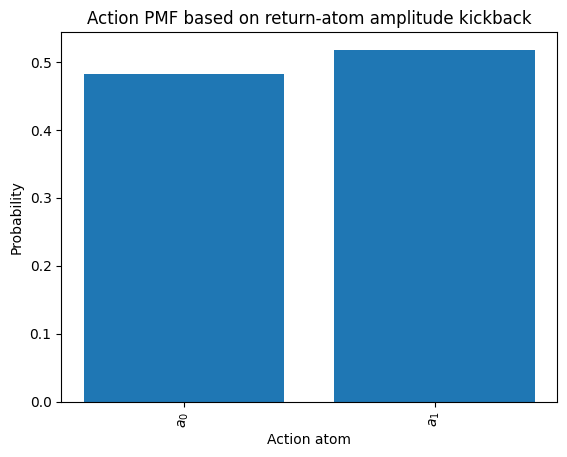

<Figure size 640x480 with 0 Axes>

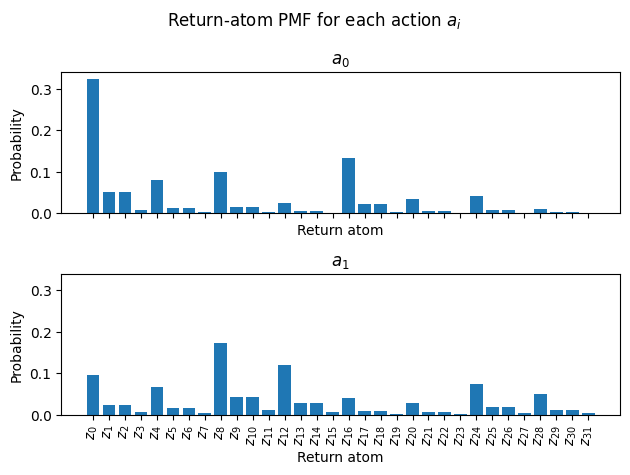

<Figure size 640x480 with 0 Axes>

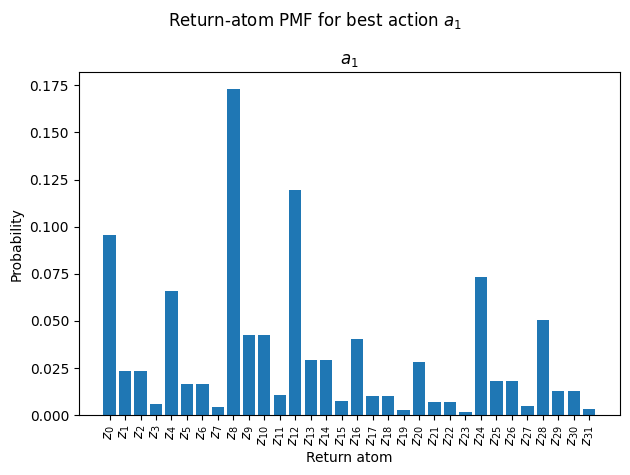

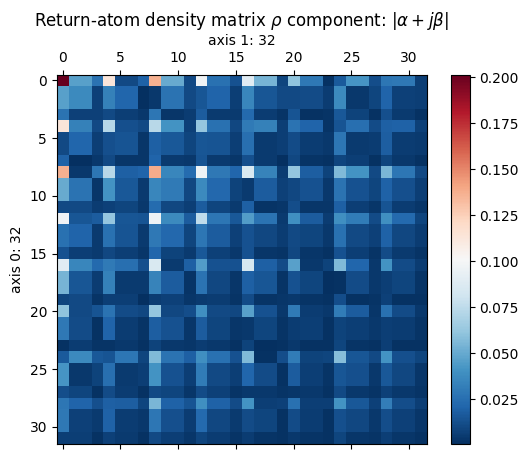

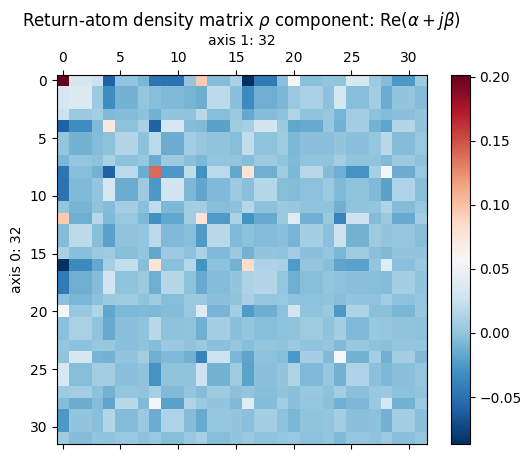

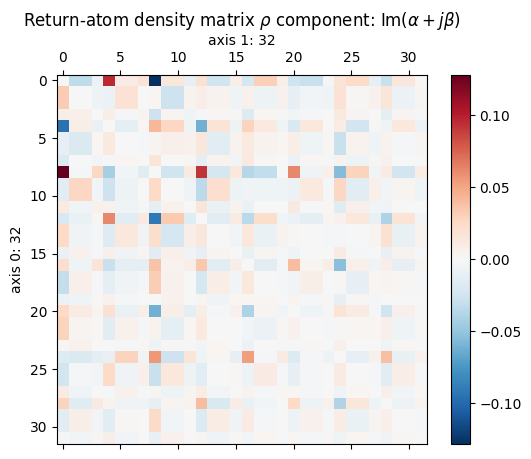

In [15]:
# Inspect density matrices before training.
# Preserve the observation that was used to compare inspect after training.
obs_inspect = inspect_model_pmfs_for_env(config.env.make(), config.model)

In [16]:
# ### Draw quantum circuit.

# key = jax.random.PRNGKey(0)
# device_name = 'default.mixed'
# shots = None
# diff_method = "backprop"

# model = config.model
# inputs = jax.random.normal(key=key, shape=(1, model.circ_observation_shape_in))
# weights = model.circ_weights_var
# probs_actions = jnp.ones(shape=(model.n_actions,))
# n_actions = model.n_actions
# d_actions = model.d_actions
# d_returns = model.d_returns
# n_layers = model.n_layers
# pauli_enc = model.pauli_enc
# pauli_var = model.pauli_var

# device = qml.device(name=device_name, shots=shots, seed=key)
# qnode = qml.QNode(func=circuit_return_dist, device=device, interface="jax", diff_method=diff_method)
# # print(qml.draw(qnode, level='device')(
# #     inputs=inputs,
# #     # probs_actions=probs_actions,
# #     probs_actions=jnp.array([1/np.sqrt(2), 1/np.sqrt(2)]),
# #     weights=weights,
# #     n_actions=n_actions,
# #     d_actions=d_actions,
# #     d_returns=d_returns,
# #     n_layers=n_layers,
# # ))

# observation_proj = model.project_observations(inputs)

# fig, ax = qml.draw_mpl(qnode, level='device', style='sketch', decimals=2)(
#     inputs=observation_proj,
#     # probs_actions=probs_actions,
#     probs_actions=jnp.array([1/np.sqrt(2), 1/np.sqrt(2)]),
#     weights=weights,
#     n_actions=n_actions,
#     d_actions=d_actions,
#     d_returns=d_returns,
#     n_layers=n_layers,
#     pauli_enc=pauli_enc,
#     pauli_var=pauli_var,
# )

# fig.show()

## Train

In [17]:
do_train = True
save_metrics = True
metric_filepath = Path(f"./metrics/{cfg_hash}.json")

In [18]:
if metric_filepath.exists() and not do_train:
    print(f"Loading existing train results")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    history_list = qnrl.tools.load_train_results(metric_filepath)
    history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
else:
    print(f"Training")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    
    history_list = config.train()
    history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
    
    # Preserve training results.
    if save_metrics:
        qnrl.tools.save_train_results(metric_filepath, history_list)

Training
Store: hashstore.json
Hash: 34028444-2a4d-50bb-964e-0e1455e0bc5b
History: metrics/34028444-2a4d-50bb-964e-0e1455e0bc5b.json


  0%|          | 0/50000 [00:00<?, ?step/s]/Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/jax/_src/ops/scatter.py:108: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion='standard'. In future JAX releases this will result in an error.
  warnings.warn(
100%|██████████| 50000/50000 [01:56<00:00, 427.81step/s, episode_step=49665, episode_reward=433, episode_length=433, episode_time=1.15, episode_utcisotime=2025-10-20T22:52:58.058349+00:00, loss_step=5e+4, loss=0.19549870687998938]   


Text(0, 0.5, 'episode_reward')

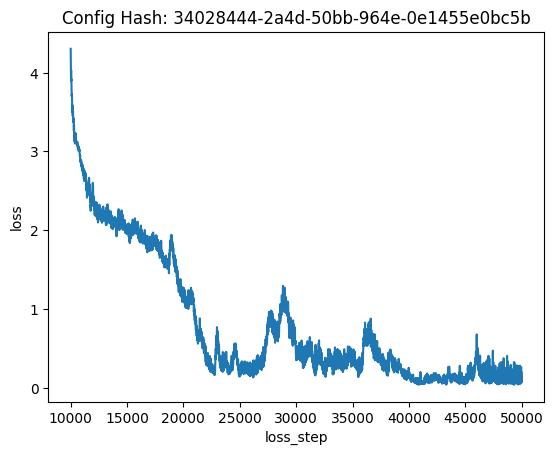

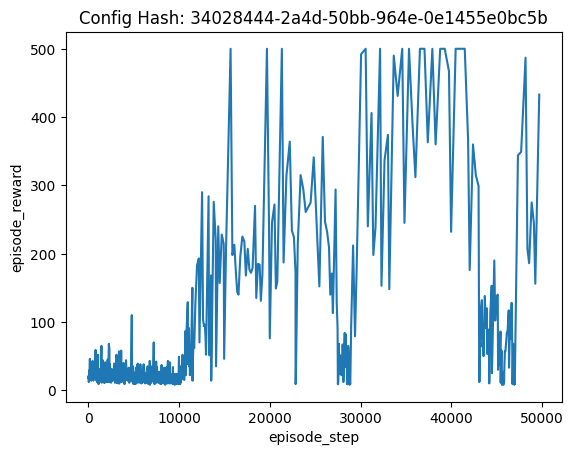

In [19]:
import matplotlib.pyplot as plt

history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))

plt.figure()
plt.title(f"Config Hash: {cfg_hash}")
plt.plot(history_dict['loss_step'], history_dict['loss'])
plt.xlabel('loss_step')
plt.ylabel('loss')

plt.figure()
plt.title(f"Config Hash: {cfg_hash}")
plt.plot(history_dict['episode_step'], history_dict['episode_reward'])
plt.xlabel('episode_step')
plt.ylabel('episode_reward')

./figures/34028444-2a4d-50bb-964e-0e1455e0bc5b.pdf


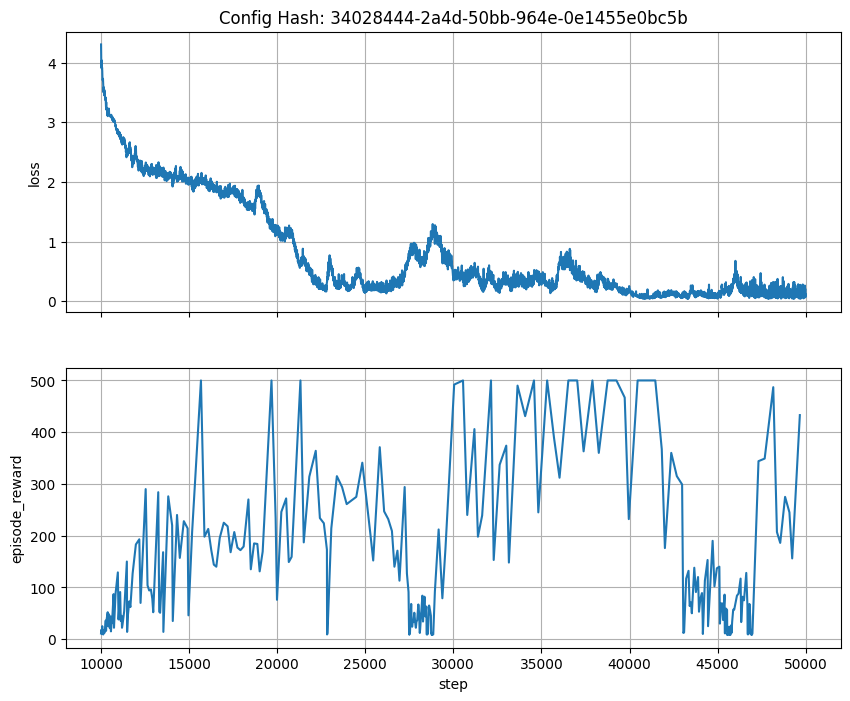

In [20]:
# Plot loss and episode reward on the same plot.

history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))

fig, axs = plt.subplots(2,1, sharex=True, figsize=(10,8))
axs = axs.squeeze()

axs[0].set_title(f"Config Hash: {cfg_hash}")
plt.xlabel('step')

# Only consider data points that are after learning starts (because this is where loss starts accumulating).
idx = np.array(history_dict['loss_step']) >= config.learning_starts
history_dict['loss_step'] = np.array(history_dict['loss_step'])[idx]
history_dict['loss'] = np.array(history_dict['loss'])[idx]

# Only consider data points that are after learning starts (because this is where loss starts accumulating).
idx = np.array(history_dict['episode_step']) >= config.learning_starts
history_dict['episode_step'] = np.array(history_dict['episode_step'])[idx]
history_dict['episode_reward'] = np.array(history_dict['episode_reward'])[idx]

axs[0].plot(history_dict['loss_step'], history_dict['loss'])
axs[0].set_ylabel('loss')
axs[0].grid() # Turn on a grid.

axs[1].plot(history_dict['episode_step'], history_dict['episode_reward'])
axs[1].set_ylabel('episode_reward')
axs[1].grid() # Turn on a grid.

# Save the figure file.
figfile = f"./figures/{cfg_hash}.pdf"
fig.savefig(figfile)
print(figfile)

P(a0): 0.5004252185999841
Q(a0): 99.57166418039866
P(a1): 0.49957478140001577
Q(a1): 98.89131030818557
observations = Array([[ 2.062714  , -0.9558324 , -0.06253485, -1.4663179 ]], dtype=float32)
best_action.item() = 0
best_return_pmf == return_pmfs[best_action.item()] = Array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True], dtype=bool)


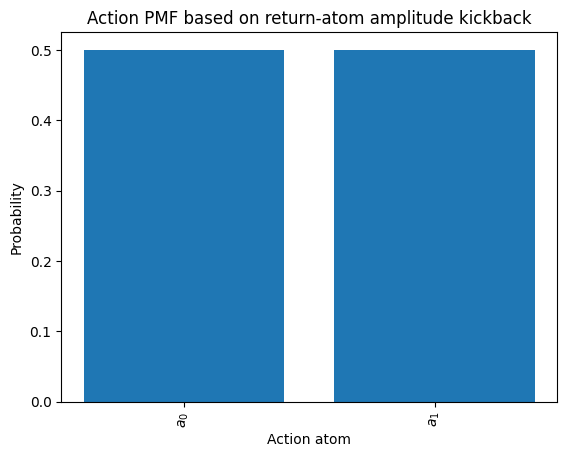

<Figure size 640x480 with 0 Axes>

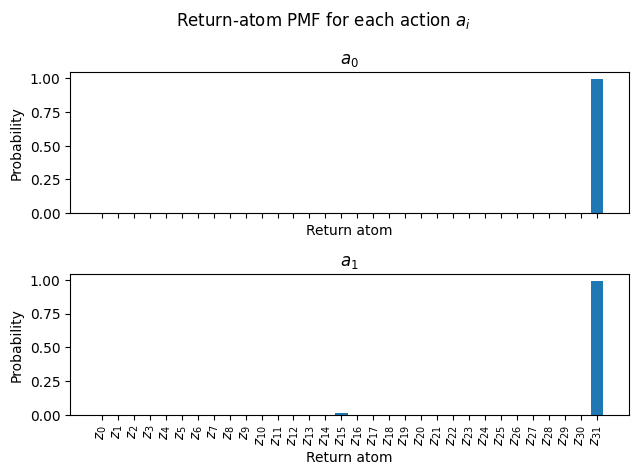

<Figure size 640x480 with 0 Axes>

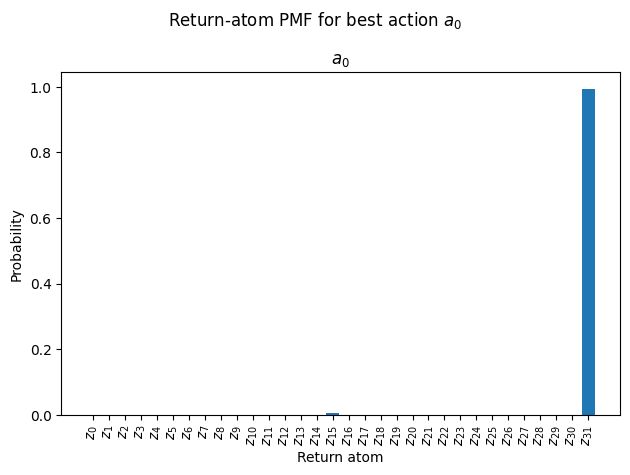

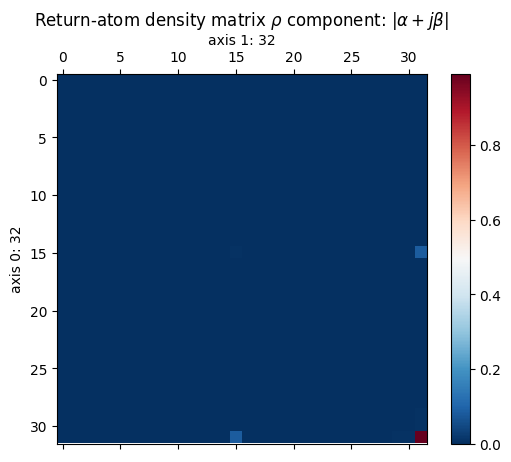

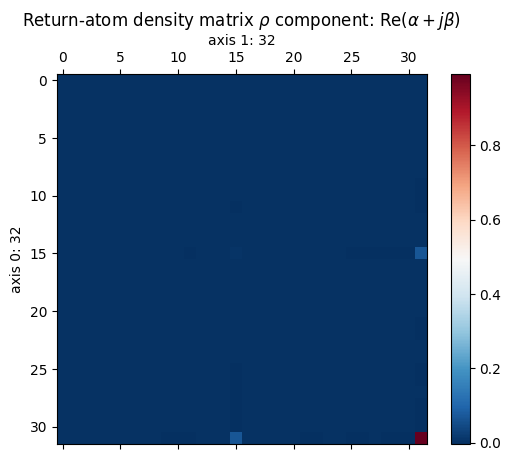

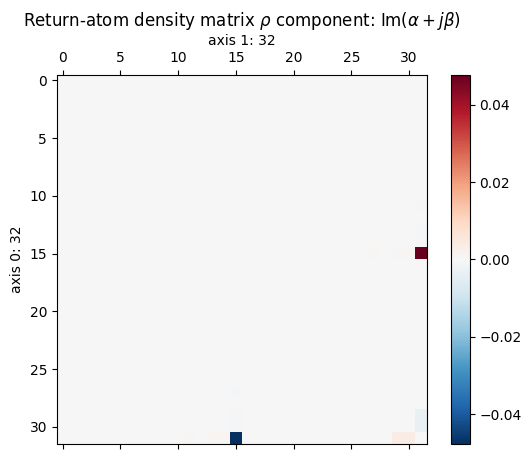

In [21]:
# Inspect the model again using the same observation used prior to training.
inspect_model_pmfs_for_observation(obs_inspect, config.model)

In [22]:
# Print all the parameters.
nnx.state(config.model, nnx.Param)

State({
  'circ_weights_enc_obs': Param( # 30 (240 B)
    value=Array([[[[-0.83875127],
             [ 0.62463341],
             [ 0.40442402],
             [-0.30530615],
             [ 0.31406191]],
    
            [[ 0.40005326],
             [ 0.63285127],
             [ 1.19439029],
             [-0.46470594],
             [ 0.4364168 ]],
    
            [[-0.54672124],
             [-0.05060375],
             [-0.78919966],
             [-0.02290658],
             [-0.11708288]]],
    
    
           [[[-0.07603609],
             [ 0.5692954 ],
             [ 0.10306234],
             [ 0.38153757],
             [ 0.68288522]],
    
            [[ 0.83641641],
             [ 0.53250673],
             [-0.12240011],
             [ 0.00126784],
             [ 0.72249402]],
    
            [[ 0.97768177],
             [-0.20967879],
             [ 0.30198699],
             [-0.29374228],
             [ 0.23077162]]]], dtype=float64)
  ),
  'circ_weights_var': Param( # 90 (720 B)

## Evaluate

In [23]:
eval_metric_list = config.eval()
eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)

for key in ('episode_step','episode_reward','episode_length','episode_time',):
    print(f"{key}: {eval_metric_dict[key][0]}")

  1%|          | 499/50000 [00:00<00:14, 3403.08step/s, episode_step=499, episode_reward=500, episode_length=500, episode_time=0.147]

episode_step: 499
episode_reward: 500.0
episode_length: 500
episode_time: 0.146779


In [24]:
# inspect_model_pmfs_for_observation(jnp.array([-0.01053775,  0.03950866, -0.03218421, -0.04678081]), config.model)

## Evaluate across multiple runs

In [25]:
# Evaluate multiple times and preserve results.
# n_runs = 10
n_runs = 50
eval_metric_dict_runs = []
for r in range(n_runs):
    eval_metric_list = config.eval()
    eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)
    eval_metric_dict_runs.append(eval_metric_dict)

# Report statistics across all runs.
for key in ('episode_step','episode_reward','episode_length','episode_time',):
    l = jnp.array([d[key][0] for d in eval_metric_dict_runs]) # Each key only has 1 entry.
    print(f"{key}: min: {jnp.min(l)}")
    print(f"{key}: max: {jnp.max(l)}")
    print(f"{key}: mean: {jnp.mean(l)}")
    print(f"{key}: std: {jnp.std(l)}")

  1%|          | 499/50000 [00:00<00:14, 3527.73step/s, episode_step=499, episode_reward=500, episode_length=500, episode_time=0.141]


episode_step: min: 499
episode_step: max: 499
episode_step: mean: 499.0
episode_step: std: 0.0
episode_reward: min: 500.0
episode_reward: max: 500.0
episode_reward: mean: 500.0
episode_reward: std: 0.0
episode_length: min: 500
episode_length: max: 500
episode_length: mean: 500.0
episode_length: std: 0.0
episode_time: min: 0.140574
episode_time: max: 0.167083
episode_time: mean: 0.14531942
episode_time: std: 0.005217117821517931
